<a href="https://www.kaggle.com/code/aritrapal3196/swiftbasket-code?scriptVersionId=357469167" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# SwiftBasket case study: which growth is worth having?
Aritra Pal · PGPM 2027, Great Lakes Institute of Management, Chennai · Straive case study #1

The COO's question: SwiftBasket is growing, but is the growth healthy? Where should we lean in, and where should we pull back?

How I worked:
1. Loaded the four sheets of the case workbook into a small SQL database (SQLite).
2. Answered each question with simple SQL and made a few bar charts.
3. Ran a few extra checks (Step 8) and re-calculated the key numbers in plain Python (Step 7).

Where I used AI: I used Claude (an AI assistant) to help write the code and draft the text. I checked the main numbers again in plain Python (Step 7), and they match the SQL.

## Step 0 · Load the data into SQL

In [1]:
import glob, os, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Find the Excel file (works on my laptop and on Kaggle)
paths = ["../data/SwiftBasket_2026_Case_Data.xlsx", "data/SwiftBasket_2026_Case_Data.xlsx"] + \
        glob.glob("/kaggle/input/**/*SwiftBasket*.xlsx", recursive=True)
excel_file = [p for p in paths if os.path.exists(p)][0]
print("Using:", excel_file)

# Put each sheet into a SQLite table with the same name
con = sqlite3.connect(":memory:")
for sheet in ["orders", "customers", "stores", "campaign_assignments"]:
    pd.read_excel(excel_file, sheet_name=sheet).to_sql(sheet, con, index=False)

# Small helper: run a SQL query and show the result as a table
def run(sql):
    return pd.read_sql(sql, con)

Using: /kaggle/input/datasets/aritrapal3196/swiftbasket/SwiftBasket_2026_Case_Data.xlsx


In [2]:
# Chart settings, so every chart looks the same
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b7b0"
CHARTS = "../charts" if os.path.isdir("../charts") else "charts"
os.makedirs(CHARTS, exist_ok=True)

def bar_chart(df, x, y, title, ylabel, highlight=None, fmt="{:.0f}", fname=None, colors=None):
    if colors is None:   # default: blue bars, orange for the ones to look at
        colors = [ORANGE if highlight is not None and i in highlight else BLUE for i in range(len(df))]
    ax = df.plot(kind="bar", x=x, y=y, legend=False, color=colors, rot=0, width=0.6)
    for i, v in enumerate(df[y]):
        label = fmt.format(v).replace("-", "−").replace("₹−", "−₹")   # show −₹10.4, not ₹-10.4
        ax.text(i, v, label, ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.axhline(0, color="#888", linewidth=0.8)
    ax.margins(y=0.12)   # room for the labels above and below the bars
    if fname: plt.savefig(f"{CHARTS}/{fname}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Step 1 · Get to know the tables

In [3]:
df = run("""
SELECT 'orders' AS table_name, COUNT(*) AS row_count FROM orders
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'stores', COUNT(*) FROM stores
UNION ALL SELECT 'campaign_assignments', COUNT(*) FROM campaign_assignments
""")
df

,table_name,row_count
0,orders,30000
1,customers,8000
2,stores,36
3,campaign_assignments,8000


In [4]:
df = run("""
SELECT * FROM orders LIMIT 5
""")
df

,order_id,customer_id,store_id,order_timestamp,promised_minutes,actual_delivery_minutes,basket_value_inr,discount_inr,delivery_fee_inr,gross_margin_inr,...,unique_category_count,stockout_item_count,substitution_count,delivery_distance_km,weather_flag,peak_period_flag,cancelled_flag,late_delivery_flag,service_contact_flag,rating
0,O0000001,C004264,S013,2025-06-08 21:11:00,30,19.0,657.44,37,29,173.46,...,5,2,2,1.40,Normal,1,0,0.0,1,4.0
1,O0000002,C006073,S035,2025-06-08 11:45:00,30,8.0,470.05,58,0,114.44,...,2,0,0,4.12,Normal,0,0,0.0,0,5.0
2,O0000003,C002271,S024,2025-10-17 22:12:00,20,12.0,558.94,6,0,180.48,...,4,0,0,0.87,Normal,0,0,0.0,0,5.0
3,O0000004,C006477,S025,2025-04-14 16:49:00,30,20.0,532.61,63,0,136.81,...,5,0,0,1.88,Heat,0,0,0.0,0,NaN
4,O0000005,C006501,S007,2025-03-24 11:18:00,25,12.0,589.65,12,0,157.88,...,5,1,1,1.93,Normal,0,0,0.0,0,4.0


In [5]:
df = run("""
SELECT MIN(order_timestamp) AS first_order, MAX(order_timestamp) AS last_order FROM orders
""")
df

,first_order,last_order
0,2025-01-01 08:19:00,2025-12-31 23:30:00


What I see: 30,000 orders from 1 Jan to 31 Dec 2025, 8,000 customers and 36 stores. One row in `orders` is one order.

One check before going further. Contribution margin is what an order leaves us after discounts, picking, delivery and refunds, before fixed costs like rent. The Data Dictionary gives its formula, so I check that the column follows it:

In [6]:
df = run("""
SELECT ROUND(SUM(gross_margin_inr + delivery_fee_inr - discount_inr - picking_cost_inr
                 - delivery_cost_inr - refund_inr - contribution_margin_inr), 2) AS difference
FROM orders
""")
df

,difference
0,0.0


The difference is 0, so the column is reliable and I can use it directly.

Next, some basic data checks: blanks, duplicates and odd values.

In [7]:
df = run("""
SELECT COUNT(*) - COUNT(DISTINCT order_id)                          AS duplicate_order_ids,
       SUM(CASE WHEN actual_delivery_minutes IS NULL THEN 1 ELSE 0 END) AS blank_delivery_time,
       SUM(cancelled_flag)                                           AS cancelled_orders,
       SUM(CASE WHEN rating IS NULL THEN 1 ELSE 0 END)               AS orders_not_rated,
       SUM(CASE WHEN basket_value_inr <= 0 THEN 1 ELSE 0 END)        AS zero_or_negative_baskets
FROM orders
""")
df

,duplicate_order_ids,blank_delivery_time,cancelled_orders,orders_not_rated,zero_or_negative_baskets
0,0,305,305,13570,0


In [8]:
df = run("""
SELECT SUM(CASE WHEN competitor_intensity IS NULL THEN 1 ELSE 0 END) AS stores_without_competition_score
FROM stores
""")
df

,stores_without_competition_score
0,3


In [9]:
df = run("""
SELECT SUM(CASE WHEN o.order_timestamp < s.launch_date THEN 1 ELSE 0 END)  AS orders_before_store_opened,
       SUM(CASE WHEN o.order_timestamp < c.signup_date THEN 1 ELSE 0 END)  AS orders_before_customer_signed_up
FROM orders o
JOIN stores s    ON o.store_id = s.store_id
JOIN customers c ON o.customer_id = c.customer_id
""")
df

,orders_before_store_opened,orders_before_customer_signed_up
0,936,4744


In [10]:
df = run("""
SELECT s.store_id, s.launch_date, COUNT(*) AS orders_before_opening
FROM orders o JOIN stores s ON o.store_id = s.store_id
WHERE o.order_timestamp < s.launch_date
GROUP BY s.store_id
ORDER BY orders_before_opening DESC
""")
df

,store_id,launch_date,orders_before_opening
0,S011,2025-06-15 00:00:00,365
1,S013,2025-04-01 00:00:00,213
2,S018,2025-03-18 00:00:00,175
3,S029,2025-03-11 00:00:00,132
4,S009,2025-01-14 00:00:00,31
5,S006,2025-01-12 00:00:00,20


In [11]:
df = run("""
SELECT COUNT(*)                      AS customers_with_no_2025_orders,
       MIN(days_since_last_order)    AS min_days_since_last_order,
       MAX(days_since_last_order)    AS max_days_since_last_order
FROM customers
WHERE historical_orders_12m = 0
""")
df

,customers_with_no_2025_orders,min_days_since_last_order,max_days_since_last_order
0,1241,60,300


In [12]:
df = run("""
SELECT SUM(CASE WHEN c.historical_orders_12m = COALESCE(o.n, 0) THEN 1 ELSE 0 END) AS customers_matching,
       COUNT(*) AS customers
FROM customers c
LEFT JOIN (SELECT customer_id, COUNT(*) AS n FROM orders GROUP BY customer_id) o
       ON c.customer_id = o.customer_id
""")
df

,customers_matching,customers
0,8000,8000


What I see:
- No duplicate orders and no zero baskets.
- 305 orders have no delivery time. These are exactly the 305 cancelled orders, which were never delivered, so that's expected. SQL's `AVG` skips blanks, so the late rate is worked out over delivered orders only.
- 45% of orders were not rated, so I treat ratings as a rough signal.
- 3 stores have no competition score ("not assessed").
- Some dates don't add up: 936 orders are dated before their store opened (mostly S011, S013, S018, S029), and 4,744 orders (16%) are dated before the customer signed up. So I don't lean on store age or signup date.
- 1,241 customers have no orders in the 2025 table, yet their "days since last order" is 60-300 days, which would put a last order inside 2025. For everyone who did order, "days since last order" matches the orders table exactly, so this looks like a data error in these 1,241 records. They make up 37% of the "lapsed + low app use" group in Step 5, and they turn out to be the customers the promo works for, so that offer needs a re-test before a full rollout.
- The customer columns `historical_orders_12m` and `historical_margin_12m` are just the 2025 orders added up, for all 8,000 customers. The Data Dictionary also marks fields like late delivery, refunds and margin as known only after an order. So I don't use these to "predict" anything in 2025. For targeting the 2026 promo I only use fields that exist before the campaign starts, which the Data Dictionary marks as known at decision time: orders in the last 12 months, days since last order and app sessions. By 2026 those really are history.

## Step 2 · Business health
Question: at a glance, how healthy is SwiftBasket?

In [13]:
kpi = run("""
SELECT COUNT(*)                                                         AS orders,
       ROUND(AVG(basket_value_inr), 0)                                  AS avg_basket_inr,
       ROUND(AVG(contribution_margin_inr), 1)                           AS margin_per_order_inr,
       ROUND(100.0 * SUM(contribution_margin_inr) / SUM(basket_value_inr), 1) AS margin_pct_of_sales,
       ROUND(100.0 * SUM(contribution_margin_inr) / SUM(basket_value_inr - discount_inr), 1) AS margin_pct_after_discount,
       ROUND(100.0 * AVG(CASE WHEN contribution_margin_inr < 0 THEN 1 ELSE 0 END), 1) AS pct_orders_losing_money,
       ROUND(100.0 * AVG(late_delivery_flag), 1)                        AS pct_late,
       ROUND(100.0 * AVG(cancelled_flag), 1)                            AS pct_cancelled,
       ROUND(AVG(rating), 2)                                            AS avg_rating
FROM orders
""")
kpi

,orders,avg_basket_inr,margin_per_order_inr,margin_pct_of_sales,margin_pct_after_discount,pct_orders_losing_money,pct_late,pct_cancelled,avg_rating
0,30000,560.0,44.3,7.9,8.6,21.0,17.3,1.0,4.21


In [14]:
money = run("""
SELECT ROUND(AVG(gross_margin_inr), 0)   AS product_margin,
       ROUND(AVG(delivery_fee_inr), 0)   AS delivery_fee_paid_by_customer,
       ROUND(AVG(discount_inr), 0)       AS discount,
       ROUND(AVG(picking_cost_inr), 0)   AS picking_cost,
       ROUND(AVG(delivery_cost_inr), 0)  AS delivery_cost,
       ROUND(AVG(refund_inr), 0)         AS refund,
       ROUND(AVG(contribution_margin_inr), 0) AS margin_left
FROM orders
""")
money

,product_margin,delivery_fee_paid_by_customer,discount,picking_cost,delivery_cost,refund,margin_left
0,161.0,6.0,45.0,21.0,36.0,21.0,44.0


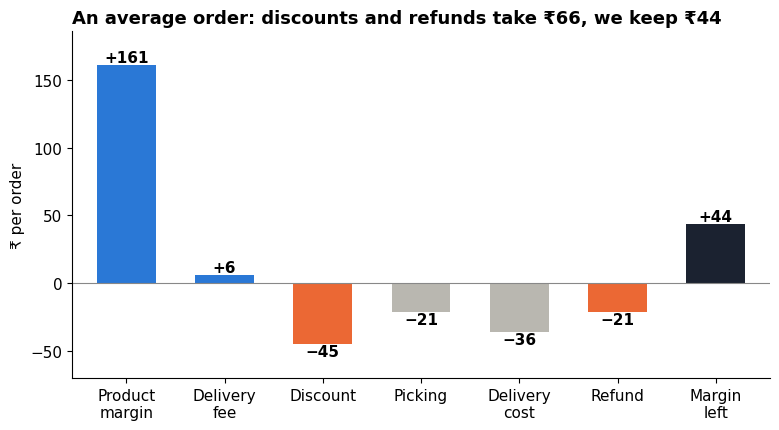

In [15]:
steps = pd.DataFrame({
    "item": ["Product\nmargin", "Delivery\nfee", "Discount", "Picking", "Delivery\ncost", "Refund", "Margin\nleft"],
    "inr":  [money.product_margin[0], money.delivery_fee_paid_by_customer[0], -money.discount[0],
             -money.picking_cost[0], -money.delivery_cost[0], -money.refund[0], money.margin_left[0]]})
bar_chart(steps, "item", "inr", "An average order: discounts and refunds take ₹66, we keep ₹44",
          "₹ per order", fmt="{:+.0f}", fname="1_where_the_money_goes",
          colors=[BLUE, BLUE, ORANGE, GREY, GREY, ORANGE, "#1b2230"])   # money in = blue, costs = grey, discounts and refunds = orange, what's left = dark

In [16]:
df = run("""
SELECT COUNT(*)                                                       AS customers,
       SUM(CASE WHEN historical_orders_12m > 0 THEN 1 ELSE 0 END)      AS customers_who_ordered_in_2025,
       ROUND(100.0 * AVG(repeat_order_30d), 1)                         AS pct_repeat_within_30_days,
       ROUND(100.0 * AVG(CASE WHEN historical_orders_12m > 0 THEN repeat_order_30d END), 1) AS pct_repeat_among_those_who_ordered
FROM customers
""")
df

,customers,customers_who_ordered_in_2025,pct_repeat_within_30_days,pct_repeat_among_those_who_ordered
0,8000,6759,30.7,36.3


In [17]:
quarters = run("""
SELECT CASE WHEN strftime('%m', order_timestamp) <= '03' THEN 'Q1'
            WHEN strftime('%m', order_timestamp) <= '06' THEN 'Q2'
            WHEN strftime('%m', order_timestamp) <= '09' THEN 'Q3'
            ELSE 'Q4' END        AS quarter,
       COUNT(*)                  AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY quarter
ORDER BY quarter
""")
quarters["change_vs_Q1_pct"] = (100 * (quarters.orders / quarters.orders[0] - 1)).round(1)
quarters

,quarter,orders,pct_late,change_vs_Q1_pct
0,Q1,7303,14.3,0.0
1,Q2,7433,18.9,1.8
2,Q3,7580,20.3,3.8
3,Q4,7684,15.5,5.2


In [18]:
df = run("""
SELECT CASE WHEN cancelled_flag = 1 THEN 'Cancelled' ELSE 'Delivered' END AS status,
       COUNT(*)                                 AS orders,
       ROUND(AVG(refund_inr), 1)                AS avg_refund,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order,
       ROUND(SUM(contribution_margin_inr), 0)   AS total_margin,
       ROUND(100.0 * SUM(contribution_margin_inr) / (SELECT SUM(contribution_margin_inr) FROM orders), 1) AS pct_of_all_margin
FROM orders
GROUP BY status
""")
df

,status,orders,avg_refund,margin_per_order,total_margin,pct_of_all_margin
0,Cancelled,305,364.6,-403.0,-122918.0,-9.3
1,Delivered,29695,17.8,48.9,1451145.0,109.3


In [19]:
monthly = run("""
SELECT strftime('%m', order_timestamp)          AS month,
       COUNT(*)                                 AS orders,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN weather_flag = 'Rain' THEN 1 ELSE 0 END), 0) AS pct_orders_in_rain
FROM orders
GROUP BY month
ORDER BY month
""")
monthly

,month,orders,margin_per_order,pct_late,pct_orders_in_rain
0,01,2505,44.4,14.9,12.0
1,02,2251,43.3,14.0,12.0
2,03,2547,45.5,14.0,13.0
3,04,2499,42.1,18.3,10.0
4,05,2520,45.0,17.0,10.0
5,06,2414,45.1,21.7,39.0
6,07,2476,46.0,19.3,41.0
7,08,2573,44.6,20.4,40.0
8,09,2531,41.3,21.2,40.0
9,10,2626,47.1,15.2,12.0


What I see:
- An average order brings in about ₹167 (₹161 product margin plus a ₹6 delivery fee). Discounts (₹45) and refunds (₹21) take ₹66 of that, more than the ₹44 we keep. (About ₹4 of the ₹21 refund is cancelled orders being refunded.)
- Margin is 7.9% of sales, and 1 in 5 orders loses money.
- About 17% of orders arrive later than promised.
- Cancellations are rare but expensive. Only 1% of orders (305) are cancelled, but each gets a refund (₹365 on average) and loses about ₹403, so together they cost about 9% of the year's margin. Delivered orders alone make about ₹49 each.
- Volume is nearly flat, about 2,500 orders every month (only about 5% more in Q4 than in Q1). Lateness goes up from June to September, the months when about 40% of orders are placed in rain (vs 12% in other months).

So the right headline number for leadership is margin per order, not order count.

## Step 3 · Which customers are worth having?
Question: what goes with customers coming back, and with them being profitable?

In [20]:
disc = run("""
SELECT CASE WHEN discount_inr = 0   THEN '1. No discount'
            WHEN discount_inr <= 25 THEN '2. ₹1-25'
            WHEN discount_inr <= 50 THEN '3. ₹26-50'
            WHEN discount_inr <= 75 THEN '4. ₹51-75'
            ELSE '5. ₹76+' END                AS discount_size,
       COUNT(*)                               AS orders,
       ROUND(AVG(basket_value_inr), 0)        AS avg_basket,
       ROUND(AVG(contribution_margin_inr), 1) AS margin_per_order
FROM orders
GROUP BY discount_size
ORDER BY discount_size
""")
disc

,discount_size,orders,avg_basket,margin_per_order
0,1. No discount,1230,559.0,87.1
1,2. ₹1-25,5604,559.0,72.3
2,3. ₹26-50,11196,561.0,49.7
3,4. ₹51-75,8631,559.0,28.2
4,5. ₹76+,3339,557.0,4.9


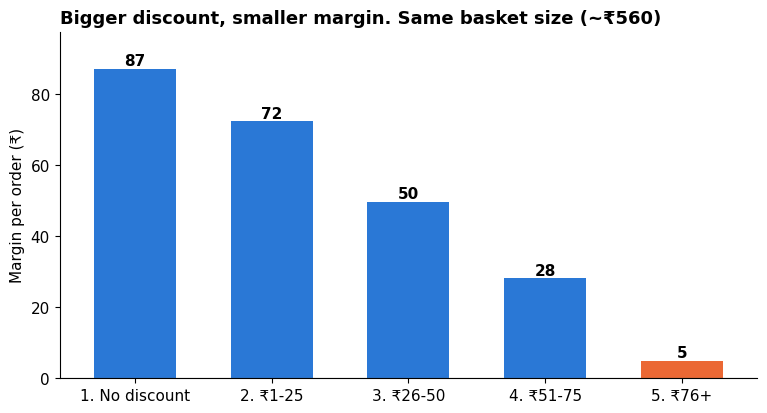

In [21]:
bar_chart(disc, "discount_size", "margin_per_order", "Bigger discount, smaller margin. Same basket size (~₹560)",
          "Margin per order (₹)", highlight=[4], fname="2_discount_vs_margin")

In [22]:
freq = run("""
SELECT CASE WHEN c.historical_orders_12m = 1  THEN '1. 1 order'
            WHEN c.historical_orders_12m <= 3 THEN '2. 2-3 orders'
            WHEN c.historical_orders_12m <= 6 THEN '3. 4-6 orders'
            WHEN c.historical_orders_12m <= 10 THEN '4. 7-10 orders'
            ELSE '5. 11+ orders' END             AS orders_in_2025,
       COUNT(DISTINCT c.customer_id)              AS customers,
       ROUND(AVG(o.discount_inr), 0)              AS avg_discount,
       ROUND(AVG(o.contribution_margin_inr), 1)   AS margin_per_order,
       ROUND(SUM(o.contribution_margin_inr) / COUNT(DISTINCT c.customer_id), 0) AS margin_per_customer_in_year
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY orders_in_2025
ORDER BY orders_in_2025
""")
freq

,orders_in_2025,customers,avg_discount,margin_per_order,margin_per_customer_in_year
0,1. 1 order,1295,33.0,56.6,57.0
1,2. 2-3 orders,2149,36.0,52.3,129.0
2,3. 4-6 orders,1850,40.0,49.4,238.0
3,4. 7-10 orders,982,48.0,41.1,337.0
4,5. 11+ orders,483,57.0,32.1,427.0


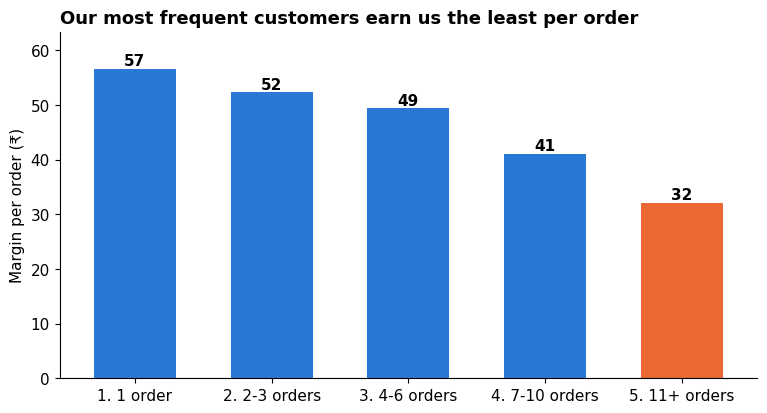

In [23]:
bar_chart(freq, "orders_in_2025", "margin_per_order", "Our most frequent customers earn us the least per order",
          "Margin per order (₹)", highlight=[4], fname="3_frequent_customers")

In [24]:
df = run("""
SELECT 'Membership' AS split, membership_status AS grp, COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers GROUP BY membership_status
UNION ALL
SELECT 'Channel', acquisition_channel, COUNT(*), ROUND(100.0 * AVG(repeat_order_30d), 1)
FROM customers GROUP BY acquisition_channel
UNION ALL
SELECT 'City tier', city_tier, COUNT(*), ROUND(100.0 * AVG(repeat_order_30d), 1)
FROM customers GROUP BY city_tier
""")
df

,split,grp,customers,pct_repeat
0,Membership,Annual member,1612,31.6
1,Membership,Monthly member,2017,31.0
2,Membership,Non-member,4371,30.1
3,Channel,Affiliate,1178,29.7
4,Channel,Marketplace,1198,31.9
5,Channel,Organic,2390,31.7
6,Channel,Paid Social,2015,29.9
7,Channel,Referral,1219,29.7
8,City tier,Metro,4026,31.0
9,City tier,Tier 2,3974,30.3


In [25]:
df = run("""
SELECT first_order_offer_inr, COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers
GROUP BY first_order_offer_inr
""")
df

,first_order_offer_inr,customers,pct_repeat
0,0,2261,30.5
1,50,1138,30.6
2,75,1134,29.3
3,100,1198,32.8
4,112,1145,29.9
5,150,1124,31.0


In [26]:
app = run("""
SELECT CASE WHEN app_sessions_30d <= 3  THEN '1. 0-3 sessions'
            WHEN app_sessions_30d <= 7  THEN '2. 4-7 sessions'
            WHEN app_sessions_30d <= 12 THEN '3. 8-12 sessions'
            ELSE '4. 13+ sessions' END AS app_use,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers
GROUP BY app_use
ORDER BY app_use
""")
app

,app_use,customers,pct_repeat
0,1. 0-3 sessions,2013,10.4
1,2. 4-7 sessions,2127,21.1
2,3. 8-12 sessions,2074,34.0
3,4. 13+ sessions,1786,61.0


In [27]:
basket = run("""
SELECT CASE WHEN basket_value_inr < 400 THEN '1. under ₹400'
            WHEN basket_value_inr < 500 THEN '2. ₹400-499'
            WHEN basket_value_inr < 600 THEN '3. ₹500-599'
            WHEN basket_value_inr < 700 THEN '4. ₹600-699'
            ELSE '5. ₹700+' END                                      AS basket_size,
       COUNT(*)                                                       AS orders,
       ROUND(AVG(discount_inr), 1)                                    AS avg_discount,
       ROUND(AVG(contribution_margin_inr), 1)                         AS margin_per_order,
       ROUND(100.0 * AVG(CASE WHEN contribution_margin_inr < 0 THEN 1 ELSE 0 END), 1) AS pct_losing_money
FROM orders
GROUP BY basket_size
ORDER BY basket_size
""")
basket

,basket_size,orders,avg_discount,margin_per_order,pct_losing_money
0,1. under ₹400,2694,44.9,-10.4,57.2
1,2. ₹400-499,6508,44.6,17.7,28.9
2,3. ₹500-599,9809,44.9,41.6,17.6
3,4. ₹600-699,7420,44.7,66.9,11.5
4,5. ₹700+,3569,44.9,94.3,8.4


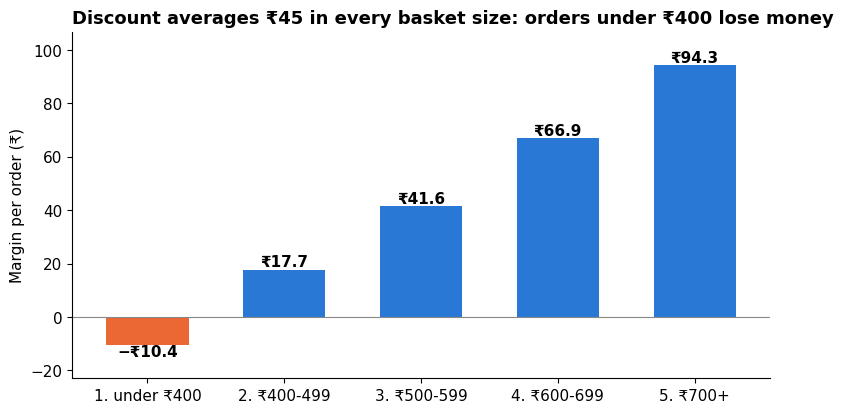

In [28]:
bar_chart(basket, "basket_size", "margin_per_order", "Discount averages ₹45 in every basket size: orders under ₹400 lose money",
          "Margin per order (₹)", highlight=[0], fmt="₹{:.1f}", fname="7_small_baskets")

In [29]:
df = run("""
SELECT c.membership_status,
       COUNT(*)                                AS orders,
       ROUND(AVG(o.discount_inr), 1)           AS avg_discount,
       ROUND(AVG(o.delivery_fee_inr), 1)       AS avg_delivery_fee,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.membership_status
""")
df

,membership_status,orders,avg_discount,avg_delivery_fee,margin_per_order
0,Annual member,5941,36.5,0.0,46.6
1,Monthly member,7944,37.7,0.0,45.4
2,Non-member,16115,51.3,11.9,42.9


In [30]:
df = run("""
SELECT delivery_fee_inr, COUNT(*) AS orders, ROUND(AVG(contribution_margin_inr), 1) AS margin_per_order
FROM orders
GROUP BY delivery_fee_inr
""")
df

,delivery_fee_inr,orders,margin_per_order
0,0,21977,40.1
1,19,4023,49.5
2,29,4000,61.7


In [31]:
df = run("""
SELECT c.acquisition_channel,
       COUNT(*) AS orders,
       ROUND(AVG(o.discount_inr), 1)            AS avg_discount,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.acquisition_channel
""")
df

,acquisition_channel,orders,avg_discount,margin_per_order
0,Affiliate,4436,44.2,45.4
1,Marketplace,4593,44.9,44.3
2,Organic,9030,45.3,43.6
3,Paid Social,7534,44.9,43.4
4,Referral,4407,44.0,46.0


In [32]:
df = run("""
SELECT 'Impressions (30 days)' AS signal,
       CASE WHEN campaign_impressions_30d <= 4 THEN '1. 0-4'
            WHEN campaign_impressions_30d <= 9 THEN '2. 5-9' ELSE '3. 10+' END AS bucket,
       COUNT(*) AS customers, ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat
FROM customers GROUP BY signal, bucket
UNION ALL
SELECT 'Clicks (30 days)', CAST(campaign_clicks_30d AS TEXT), COUNT(*), ROUND(100.0 * AVG(repeat_order_30d), 1)
FROM customers GROUP BY campaign_clicks_30d
""")
df

,signal,bucket,customers,pct_repeat
0,Impressions (30 days),1. 0-4,2491,29.7
1,Impressions (30 days),2. 5-9,2480,30.7
2,Impressions (30 days),3. 10+,3029,31.4
3,Clicks (30 days),0,2230,30.5
4,Clicks (30 days),1,1763,31.8
5,Clicks (30 days),2,1504,29.5
6,Clicks (30 days),3,1338,30.5
7,Clicks (30 days),4,1165,30.9


In [33]:
df = run("""
SELECT strftime('%Y', signup_date) || CASE WHEN strftime('%m', signup_date) <= '06' THEN ' H1' ELSE ' H2' END AS signed_up,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1) AS pct_repeat,
       ROUND(AVG(historical_orders_12m), 2)    AS orders_in_2025
FROM customers
GROUP BY signed_up
ORDER BY signed_up
""")
df

,signed_up,customers,pct_repeat,orders_in_2025
0,2024 H1,2263,30.0,3.63
1,2024 H2,2299,31.0,3.75
2,2025 H1,2282,31.1,3.89
3,2025 H2,1156,30.4,3.71


In [34]:
df = run("""
SELECT SUM(CASE WHEN historical_orders_12m = 0 THEN 1 ELSE 0 END) AS never_ordered,
       SUM(CASE WHEN historical_orders_12m > 0 AND historical_margin_12m < 0 THEN 1 ELSE 0 END) AS lost_us_money_in_2025,
       SUM(CASE WHEN historical_orders_12m > 0 THEN 1 ELSE 0 END) AS ordered_at_least_once
FROM customers
""")
df

,never_ordered,lost_us_money_in_2025,ordered_at_least_once
0,1241,593,6759


What I see:
- Discounts eat margin. Basket size is the same (~₹560) whatever the discount, so the discount isn't making people buy more. An order with no discount leaves ₹87; an order with ₹76+ off leaves ₹5.
- Our busiest customers earn us the least per order. Customers with 11+ orders a year get ₹57 off on average, against ₹33 for one-time customers, so their margin per order is ₹32 against ₹57. They're still our most valuable customers in total (about ₹427 each over the year vs ₹57 for one-time customers), so the fix is smaller discounts, not losing them. This is the COO's worry, and the data partly backs it.
- Membership, channel, city tier and the size of the first-order offer make almost no difference to repeat rates (all between 29% and 33%).
- App use does. Customers with 13+ app sessions a month repeat at 61%, against 10% for 0-3 sessions. (This shows the two go together, not that one causes the other.)
- Small baskets lose money. The discount doesn't grow with the basket: it averages about ₹45 in every basket size. So orders under ₹400 lose ₹10.4 on average, and 57% of them lose money. Orders of ₹700+ make ₹94.
- Members earn us more per order. Members pay no delivery fee, but they get smaller discounts (₹36-38 vs ₹51), so their margin per order is higher (₹45-47 vs ₹43). Orders that pay a ₹29 delivery fee make ₹62, against ₹40 for free-delivery orders.
- Not much difference by acquisition channel (₹43-46 per order), marketing impressions or clicks (repeat stays 29-32%), or signup date (repeat 30-31% for every half-year).
- 1,241 customers (16%) have no orders in the 2025 table (see the date caveat in Step 1), and 593 of the 6,759 who did order lost us money over the year.

## Step 4 · Operations: where are we losing money?

In [35]:
df = run("""
SELECT promised_minutes, COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late,
       ROUND(AVG(delivery_distance_km), 1)        AS avg_distance_km
FROM orders
GROUP BY promised_minutes
""")
df

,promised_minutes,orders,pct_late,avg_distance_km
0,20,7442,40.4,2.5
1,25,7464,17.8,2.5
2,30,15094,5.6,2.5


In [36]:
promise = run("""
SELECT CASE WHEN delivery_distance_km <= 2 THEN '1. 0-2 km'
            WHEN delivery_distance_km <= 4 THEN '2. 2-4 km'
            ELSE '3. over 4 km' END AS distance,
       promised_minutes,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY distance, promised_minutes
ORDER BY distance, promised_minutes
""")
promise

,distance,promised_minutes,orders,pct_late
0,1. 0-2 km,20,2739,22.3
1,1. 0-2 km,25,2747,5.4
2,1. 0-2 km,30,5520,1.1
3,2. 2-4 km,20,3771,45.7
4,2. 2-4 km,25,3786,19.6
5,2. 2-4 km,30,7609,5.2
6,3. over 4 km,20,932,72.5
7,3. over 4 km,25,931,47.2
8,3. over 4 km,30,1965,19.8


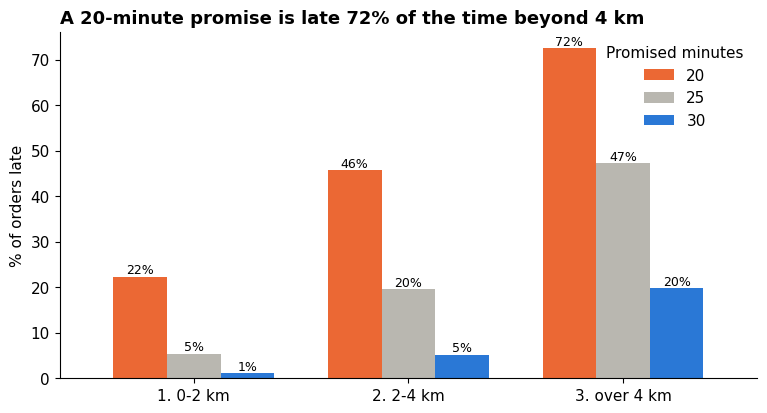

promised_minutes,20,25,30
distance,,,
1. 0-2 km,22.3,5.4,1.1
2. 2-4 km,45.7,19.6,5.2
3. over 4 km,72.5,47.2,19.8


In [37]:
table = promise.pivot(index="distance", columns="promised_minutes", values="pct_late")
ax = table.plot(kind="bar", rot=0, color=[ORANGE, GREY, BLUE], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9)
ax.set_title("A 20-minute promise is late 72% of the time beyond 4 km", loc="left")
ax.set_ylabel("% of orders late"); ax.set_xlabel(""); ax.legend(title="Promised minutes", frameon=False)
plt.savefig(f"{CHARTS}/4_promise_vs_distance.png", dpi=200, bbox_inches="tight"); plt.show()
table

In [38]:
df = run("""
SELECT weather_flag,
       CASE WHEN peak_period_flag = 1 THEN 'Peak hours' ELSE 'Other hours' END AS time_of_day,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY weather_flag, time_of_day
ORDER BY pct_late DESC
""")
df

,weather_flag,time_of_day,orders,pct_late
0,Rain,Peak hours,2293,47.5
1,Heat,Peak hours,1257,31.7
2,Rain,Other hours,4036,24.1
3,Normal,Peak hours,7520,20.1
4,Heat,Other hours,2156,15.3
5,Normal,Other hours,12738,6.9


In [39]:
df = run("""
SELECT CASE WHEN late_delivery_flag = 1 THEN 'Late' ELSE 'On time' END AS delivery,
       COUNT(*) AS orders,
       ROUND(AVG(rating), 2) AS avg_rating,
       ROUND(100.0 * AVG(service_contact_flag), 1) AS pct_contacted_support
FROM orders
WHERE cancelled_flag = 0
GROUP BY delivery
""")
df

,delivery,orders,avg_rating,pct_contacted_support
0,Late,5130,3.88,18.8
1,On time,24565,4.28,11.1


In [40]:
stock = run("""
-- Cancelled orders get large refunds (₹365 on average), so I leave them out to see the effect of missing items alone
SELECT CASE WHEN stockout_item_count = 0 THEN '0 missing'
            WHEN stockout_item_count = 1 THEN '1 missing'
            WHEN stockout_item_count = 2 THEN '2 missing'
            ELSE '3+ missing' END              AS items_missing,
       COUNT(*)                                 AS orders,
       ROUND(AVG(refund_inr), 1)                AS avg_refund,
       ROUND(AVG(rating), 2)                    AS avg_rating,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order
FROM orders
WHERE cancelled_flag = 0
GROUP BY items_missing
ORDER BY items_missing
""")
stock

,items_missing,orders,avg_refund,avg_rating,margin_per_order
0,0 missing,10510,0.0,4.95,69.9
1,1 missing,9741,27.7,4.23,39.3
2,2 missing,5475,27.5,3.69,35.9
3,3+ missing,3969,27.4,2.94,34.4


In [41]:
df = run("""
SELECT ROUND(100.0 * AVG(CASE WHEN stockout_item_count > 0 THEN 1 ELSE 0 END), 1)                 AS pct_delivered_orders_with_missing_item,
       ROUND(100.0 * AVG(CASE WHEN stockout_item_count - substitution_count > 0 THEN 1 ELSE 0 END), 1) AS pct_with_an_item_not_replaced,
       ROUND(100.0 * AVG(CASE WHEN stockout_item_count > 0 AND refund_inr > 0 THEN 1.0
                              WHEN stockout_item_count > 0 THEN 0 END), 1)                          AS pct_of_those_refunded,
       ROUND(AVG(CASE WHEN stockout_item_count > 0 AND refund_inr > 0 THEN refund_inr END), 0)      AS avg_refund_when_given
FROM orders
WHERE cancelled_flag = 0
""")
df

,pct_delivered_orders_with_missing_item,pct_with_an_item_not_replaced,pct_of_those_refunded,avg_refund_when_given
0,64.6,35.9,39.4,70.0


In [42]:
inv = run("""
SELECT CASE WHEN s.inventory_accuracy_pct < 90 THEN '1. Below 90%'
            WHEN s.inventory_accuracy_pct < 95 THEN '2. 90-95%'
            ELSE '3. 95% and above' END             AS stock_accuracy,
       COUNT(DISTINCT s.store_id)                   AS stores,
       COUNT(*)                                     AS orders,
       ROUND(AVG(o.stockout_item_count), 2)         AS missing_items_per_order,
       ROUND(AVG(o.refund_inr), 1)                  AS refund_per_order,
       ROUND(AVG(o.contribution_margin_inr), 1)     AS margin_per_order,
       ROUND(AVG(o.rating), 2)                      AS avg_rating
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY stock_accuracy
ORDER BY stock_accuracy
""")
inv

,stock_accuracy,stores,orders,missing_items_per_order,refund_per_order,margin_per_order,avg_rating
0,1. Below 90%,9,7414,1.77,26.7,38.7,3.83
1,2. 90-95%,17,14265,1.16,21.2,44.3,4.21
2,3. 95% and above,10,8321,0.62,16.8,49.3,4.54


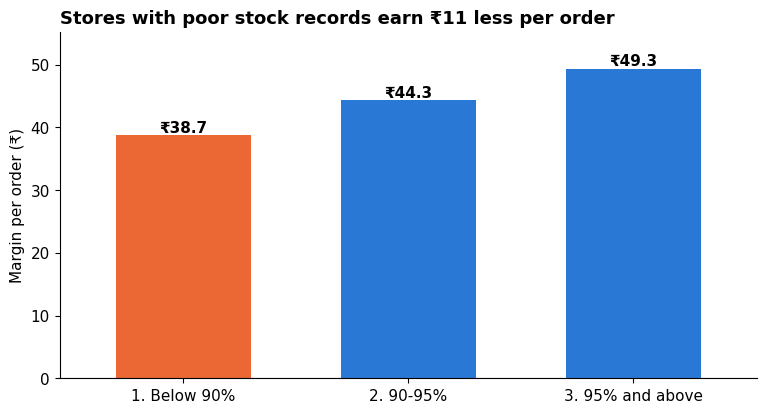

In [43]:
bar_chart(inv, "stock_accuracy", "margin_per_order", "Stores with poor stock records earn ₹11 less per order",
          "Margin per order (₹)", highlight=[0], fmt="₹{:.1f}", fname="5_stock_accuracy")

In [44]:
df = run("""
SELECT CASE WHEN s.staffing_fill_rate_pct < 80 THEN '1. Below 80%'
            WHEN s.staffing_fill_rate_pct < 90 THEN '2. 80-90%'
            ELSE '3. 90% and above' END   AS shifts_filled,
       COUNT(DISTINCT s.store_id)         AS stores,
       ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY shifts_filled
ORDER BY shifts_filled
""")
df

,shifts_filled,stores,pct_late
0,1. Below 80%,12,22.0
1,2. 80-90%,11,16.3
2,3. 90% and above,13,13.9


In [45]:
df = run("""
SELECT s.store_id, s.city, s.inventory_accuracy_pct, s.staffing_fill_rate_pct,
       COUNT(*) AS orders,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order,
       ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY s.store_id
ORDER BY margin_per_order
LIMIT 6
""")
df

,store_id,city,inventory_accuracy_pct,staffing_fill_rate_pct,orders,margin_per_order,pct_late
0,S012,Tier2 D,88.8,76.9,860,33.3,30.2
1,S011,Tier2 E,84.5,76.5,829,35.2,30.7
2,S027,Metro A,88.7,78.2,775,35.3,23.8
3,S003,Tier2 D,89.5,69.8,797,38.7,25.5
4,S008,Metro C,90.9,96.2,839,39.1,17.2
5,S016,Tier2 D,89.0,97.3,834,39.5,13.7


In [46]:
df = run("""
SELECT 'City' AS split, s.city AS grp, ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.city
UNION ALL
SELECT 'Delivery model', s.delivery_partner_model, ROUND(AVG(o.contribution_margin_inr), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.delivery_partner_model
UNION ALL
SELECT 'Store opened in', strftime('%Y', s.launch_date), ROUND(AVG(o.contribution_margin_inr), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY strftime('%Y', s.launch_date)
""")
df

,split,grp,margin_per_order
0,City,Metro A,45.1
1,City,Metro B,43.5
2,City,Metro C,46.2
3,City,Tier2 D,42.4
4,City,Tier2 E,43.4
5,City,Tier2 F,46.9
6,Delivery model,Dedicated,44.3
7,Delivery model,Hybrid,44.3
8,Delivery model,Marketplace,44.3
9,Store opened in,2023,45.3


In [47]:
df = run("""
SELECT s.city,
       COUNT(*) AS orders,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order,
       ROUND(100.0 * AVG(CASE WHEN o.cancelled_flag = 0 THEN o.late_delivery_flag END), 1) AS pct_late_delivered
FROM orders o JOIN stores s ON o.store_id = s.store_id
GROUP BY s.city
ORDER BY margin_per_order
""")
df

,city,orders,margin_per_order,pct_late_delivered
0,Tier2 D,5841,42.4,19.3
1,Tier2 E,7503,43.4,18.7
2,Metro B,2502,43.5,14.3
3,Metro A,8282,45.1,17.2
4,Metro C,3319,46.2,15.0
5,Tier2 F,2553,46.9,14.4


What I see: Tier2 D is the weakest city on both margin per order and lateness, and three of the six weakest stores (S012, S003, S016) are there. The gap between cities is small next to the gap between stores, so I act at store level.

In [48]:
hours = run("""
SELECT CAST(strftime('%H', order_timestamp) AS INTEGER) AS hour,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late
FROM orders
GROUP BY hour
ORDER BY hour
""")
hours

,hour,orders,pct_late
0,7,602,11.7
1,8,859,11.8
2,9,1093,11.4
3,10,1317,12.4
4,11,1588,11.0
5,12,1909,27.3
6,13,1661,26.9
7,14,1400,10.7
8,15,1543,11.6
9,16,2218,11.4


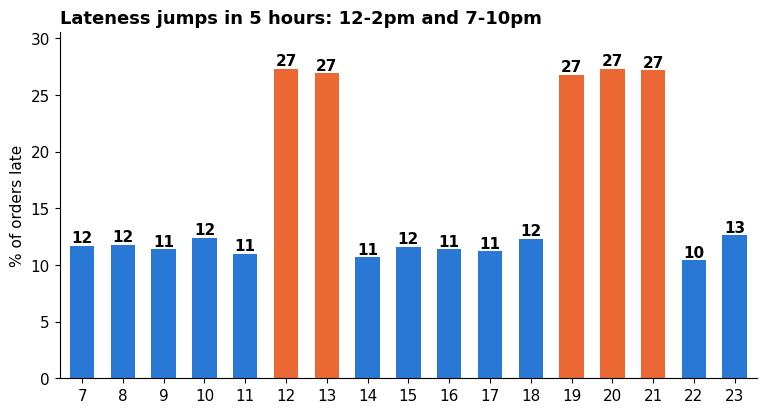

In [49]:
bar_chart(hours, "hour", "pct_late", "Lateness jumps in 5 hours: 12-2pm and 7-10pm", "% of orders late",
          highlight=[i for i, h in enumerate(hours.hour) if h in (12, 13, 19, 20, 21)], fname="8_late_by_hour")

In [50]:
df = run("""
SELECT strftime('%w', order_timestamp) AS weekday,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1) AS pct_late,
       ROUND(AVG(contribution_margin_inr), 1)    AS margin_per_order
FROM orders
GROUP BY weekday
ORDER BY weekday
""")
df

,weekday,orders,pct_late,margin_per_order
0,0,4188,17.9,44.2
1,1,4310,17.6,45.2
2,2,4242,17.1,43.3
3,3,4394,17.2,43.7
4,4,4287,17.5,44.6
5,5,4270,16.3,44.3
6,6,4309,17.3,44.5


In [51]:
df = run("""
SELECT CASE WHEN item_count <= 3 THEN '1. 1-3 items' WHEN item_count <= 6 THEN '2. 4-6 items'
            WHEN item_count <= 9 THEN '3. 7-9 items' ELSE '4. 10+ items' END AS order_size,
       COUNT(*) AS orders,
       ROUND(AVG(stockout_item_count), 2)       AS missing_items_per_order,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order
FROM orders
GROUP BY order_size
ORDER BY order_size
""")
df

,order_size,orders,missing_items_per_order,margin_per_order
0,1. 1-3 items,4778,0.38,61.4
1,2. 4-6 items,10214,0.90,48.5
2,3. 7-9 items,10284,1.41,38.6
3,4. 10+ items,4724,1.96,30.2


In [52]:
df = run("""
SELECT stockout_item_count - substitution_count AS items_not_replaced,
       COUNT(*)                   AS orders,
       ROUND(AVG(refund_inr), 1)  AS avg_refund,
       ROUND(AVG(rating), 2)      AS avg_rating
FROM orders
WHERE stockout_item_count > 0
GROUP BY items_not_replaced
ORDER BY items_not_replaced
""")
df

,items_not_replaced,orders,avg_refund,avg_rating
0,0,8518,27.0,4.01
1,1,8023,28.3,3.82
2,2,2096,26.9,3.27
3,3,457,27.0,2.66
4,4,82,28.4,2.24
5,5,9,25.6,1.88


In [53]:
df = run("""
SELECT CASE WHEN late_delivery_flag = 1 THEN 'Late' ELSE 'On time' END            AS delivery,
       CASE WHEN stockout_item_count > 0 THEN 'Items missing' ELSE 'Complete' END AS basket,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(service_contact_flag), 1) AS pct_contacted_support,
       ROUND(AVG(rating), 2) AS avg_rating
FROM orders
WHERE cancelled_flag = 0
GROUP BY delivery, basket
ORDER BY pct_contacted_support
""")
df

,delivery,basket,orders,pct_contacted_support,avg_rating
0,On time,Complete,8786,1.9,5.00
1,Late,Complete,1724,8.9,4.71
2,On time,Items missing,15779,16.2,3.88
3,Late,Items missing,3406,23.8,3.49


In [54]:
df = run("""
SELECT 'Store format' AS split, s.store_format AS grp, COUNT(DISTINCT s.store_id) AS stores,
       ROUND(AVG(o.contribution_margin_inr), 1) AS margin_per_order, ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.store_format
UNION ALL
SELECT 'Catchment density', s.catchment_density, COUNT(DISTINCT s.store_id),
       ROUND(AVG(o.contribution_margin_inr), 1), ROUND(100.0 * AVG(o.late_delivery_flag), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY s.catchment_density
UNION ALL
SELECT 'Competition', COALESCE(s.competitor_intensity, 'Not assessed'), COUNT(DISTINCT s.store_id),
       ROUND(AVG(o.contribution_margin_inr), 1), ROUND(100.0 * AVG(o.late_delivery_flag), 1)
FROM orders o JOIN stores s ON o.store_id = s.store_id GROUP BY COALESCE(s.competitor_intensity, 'Not assessed')
""")
df

,split,grp,stores,margin_per_order,pct_late
0,Store format,Large,8,46.0,16.8
1,Store format,Small,8,45.1,17.2
2,Store format,Standard,20,43.3,17.5
3,Catchment density,High,8,46.6,18.1
4,Catchment density,Low,16,41.7,19.2
5,Catchment density,Medium,12,46.1,14.1
6,Competition,High,20,43.9,17.0
7,Competition,Low,5,42.1,22.1
8,Competition,Medium,8,44.0,15.4
9,Competition,Not assessed,3,51.1,15.8


In [55]:
df = run("""
SELECT CASE WHEN s.average_active_riders < 25 THEN '1. under 25 riders'
            WHEN s.average_active_riders < 40 THEN '2. 25-39 riders' ELSE '3. 40+ riders' END AS riders_per_shift,
       COUNT(DISTINCT s.store_id) AS stores,
       ROUND(100.0 * AVG(o.late_delivery_flag), 1) AS pct_late
FROM orders o
JOIN stores s ON o.store_id = s.store_id
GROUP BY riders_per_shift
ORDER BY riders_per_shift
""")
df

,riders_per_shift,stores,pct_late
0,1. under 25 riders,10,20.1
1,2. 25-39 riders,16,16.7
2,3. 40+ riders,10,15.4


In [56]:
df = run("""
SELECT store_id,
       SUM(CASE WHEN strftime('%m', order_timestamp) <= '06' THEN 1 ELSE 0 END) AS orders_jan_jun,
       SUM(CASE WHEN strftime('%m', order_timestamp) >  '06' THEN 1 ELSE 0 END) AS orders_jul_dec,
       ROUND(AVG(contribution_margin_inr), 1) AS margin_per_order
FROM orders
GROUP BY store_id
ORDER BY 1.0 * orders_jul_dec / orders_jan_jun DESC
LIMIT 6
""")
df

,store_id,orders_jan_jun,orders_jul_dec,margin_per_order
0,S004,381,456,48.4
1,S034,354,410,51.8
2,S016,393,441,39.5
3,S002,359,402,48.2
4,S029,377,422,43.5
5,S008,400,439,39.1


In [57]:
df = run("""
SELECT weather_flag,
       CASE WHEN peak_period_flag = 1 THEN 'Peak hours' ELSE 'Other hours' END AS time_of_day,
       ROUND(100.0 * AVG(cancelled_flag), 2) AS pct_cancelled
FROM orders
GROUP BY weather_flag, time_of_day
ORDER BY pct_cancelled DESC
""")
df

,weather_flag,time_of_day,pct_cancelled
0,Heat,Peak hours,1.43
1,Normal,Other hours,1.08
2,Rain,Peak hours,1.05
3,Normal,Peak hours,1.02
4,Rain,Other hours,0.82
5,Heat,Other hours,0.74


What I see:
- The delivery promise doesn't depend on distance. 20-, 25- and 30-minute promises all go to orders with the same average distance (2.5 km). So 20-minute promises are late 40% of the time overall, and 72% of the time beyond 4 km.
- Rain at peak hours is the worst slot: 47.5% late, against 6.9% at normal off-peak times.
- Late orders cost us: rating 3.88 vs 4.28, and 18.8% of late orders contact support vs 11.1%.
- Stock-outs are what cause refunds, and they're common. About 2 in 3 delivered orders (65%) hit a stock-out (an item unavailable at picking); about 1 in 3 (36%) arrive with an item not replaced. With nothing missing the refund is ₹0; with any item missing it averages about ₹28 (only about 4 in 10 of those orders get a refund, about ₹70 when they do). Margin drops from about ₹70 to about ₹39 per order. Ratings drop from 4.95 to 2.94 when three or more items are missing.
- Stock accuracy explains a lot of the store gap. The 9 stores whose stock records are below 90% accurate earn ₹38.7 per order, against ₹49.3 for stores at 95%+. Their extra refunds (about ₹27 vs ₹21 per order) are about the same size as their margin gap to the 90-95% stores (₹5.6), which fits the stock-out story. They're also worse staffed, though, so only a pilot can separate the two.
- Under-staffed stores are late more often (22% vs 14%).
- Delivery model makes no difference (₹44.3 per order for all three). City matters a little (14-19% late), but less than what happens inside the stores. I don't read anything into store age, because some orders are dated before their store opened (Step 1).
- Lateness is about time of day, not day of week. It jumps from about 11% to about 27% in exactly five hours (12-2pm and 7-10pm), which are exactly the hours the data flags as peak. Every weekday sits at 16-18%.
- Bigger orders have more missing items (0.4 per order for 1-3 items, 2.0 for 10+), and their margin falls from ₹61 to ₹30.
- Substitutes help a little. Among orders with something missing, the rating is 4.01 when every missing item was replaced, 3.82 with one item not replaced and 3.27 with two.
- Late and incomplete together is the worst case: 23.8% of those orders contact support, against 1.9% for on-time, complete orders.
- Fewer riders, more lateness: 20% late in stores with under 25 riders per shift, against 15% with 40+.
- Store format, catchment density and competition change margin by only a few rupees. Low-density areas are a little worse (₹41.7 per order, 19% late).
- Fast growth isn't the problem. The fastest-growing stores (S004, S034) have good margins (₹48-52); the store problems line up with stock accuracy, not growth.
- Cancellations are about 1% in every weather and time slot, so there's no single place to fix them. They still cost about 9% of margin, so they're worth watching.

## Step 5 · The promotion: who should get an offer?
The Q1 campaign was a proper experiment. Customers were randomly put in a Control group (no offer) or a Treatment group (one of three offers). Because it was random, the two groups are alike, so any difference after the campaign is caused by the offer.

The key idea: an offer only pays if it brings in extra profit compared with doing nothing. Redemption alone doesn't tell us that, because some people would have bought anyway.

In [58]:
df = run("""
SELECT a.offer_type,
       COUNT(*) AS customers,
       ROUND(AVG(c.days_since_last_order), 0) AS avg_days_since_last_order,
       ROUND(AVG(c.app_sessions_30d), 1)      AS avg_app_sessions,
       ROUND(AVG(c.historical_orders_12m), 1) AS avg_orders_2025
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY a.offer_type
""")
df

,offer_type,customers,avg_days_since_last_order,avg_app_sessions,avg_orders_2025
0,Fixed discount,1573,109.0,8.2,3.7
1,Free delivery,1559,107.0,8.2,3.7
2,No offer,2832,106.0,8.3,3.8
3,Percentage discount,2036,105.0,8.4,3.8


In [59]:
df = run("""
SELECT assignment_group,
       COUNT(*) AS customers,
       ROUND(AVG(post_campaign_orders), 2)     AS orders_per_customer,
       ROUND(AVG(post_campaign_margin_inr), 1) AS margin_per_customer
FROM campaign_assignments
GROUP BY assignment_group
""")
df

,assignment_group,customers,orders_per_customer,margin_per_customer
0,Control,2832,1.21,78.8
1,Treatment,5168,1.37,66.4


In [60]:
df = run("""
SELECT offer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(offer_redeemed_flag), 1) AS pct_redeemed,
       ROUND(AVG(post_campaign_orders), 2)        AS orders_per_customer,
       ROUND(AVG(post_campaign_margin_inr), 1)    AS margin_per_customer
FROM campaign_assignments
GROUP BY offer_type
ORDER BY margin_per_customer DESC
""")
df

,offer_type,customers,pct_redeemed,orders_per_customer,margin_per_customer
0,No offer,2832,0.0,1.21,78.8
1,Free delivery,1559,31.8,1.37,76.7
2,Percentage discount,2036,32.0,1.35,64.7
3,Fixed discount,1573,31.7,1.38,58.2


In [61]:
promo = run("""
SELECT CASE WHEN c.days_since_last_order <= 90 THEN '1. Active (ordered in last 90 days)'
            ELSE '2. Lapsed (no order for 91+ days)' END AS customer_type,
       a.offer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(a.offer_redeemed_flag), 1) AS pct_redeemed,
       ROUND(AVG(a.post_campaign_orders), 2)        AS orders_per_customer,
       AVG(a.post_campaign_margin_inr)              AS margin_per_customer
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY customer_type, a.offer_type
ORDER BY customer_type, a.offer_type
""")
promo

,customer_type,offer_type,customers,pct_redeemed,orders_per_customer,margin_per_customer
0,1. Active (ordered in last 90 days),Fixed discount,821,37.6,1.71,73.097308
1,1. Active (ordered in last 90 days),Free delivery,835,36.3,1.73,98.171796
2,1. Active (ordered in last 90 days),No offer,1515,0.0,1.62,106.213617
3,1. Active (ordered in last 90 days),Percentage discount,1111,36.5,1.70,84.500072
4,2. Lapsed (no order for 91+ days),Fixed discount,752,25.1,1.02,41.874149
5,2. Lapsed (no order for 91+ days),Free delivery,724,26.5,0.95,51.975732
6,2. Lapsed (no order for 91+ days),No offer,1317,0.0,0.73,47.297752
7,2. Lapsed (no order for 91+ days),Percentage discount,925,26.5,0.93,41.008638


In [62]:
# Extra margin = offer group's margin minus the no-offer group's margin, within the same customer type
base = promo[promo.offer_type == "No offer"].set_index("customer_type")["margin_per_customer"]
promo["extra_margin_vs_no_offer"] = promo.apply(lambda r: round(r.margin_per_customer - base[r.customer_type], 1), axis=1)
promo["margin_per_customer"] = promo["margin_per_customer"].round(1)   # round only after subtracting
promo[promo.offer_type != "No offer"][["customer_type", "offer_type", "pct_redeemed", "extra_margin_vs_no_offer"]]

,customer_type,offer_type,pct_redeemed,extra_margin_vs_no_offer
0,1. Active (ordered in last 90 days),Fixed discount,37.6,-33.1
1,1. Active (ordered in last 90 days),Free delivery,36.3,-8.0
3,1. Active (ordered in last 90 days),Percentage discount,36.5,-21.7
4,2. Lapsed (no order for 91+ days),Fixed discount,25.1,-5.4
5,2. Lapsed (no order for 91+ days),Free delivery,26.5,4.7
7,2. Lapsed (no order for 91+ days),Percentage discount,26.5,-6.3


Lapsed customers look better than active ones, but some lapsed customers still open the app a lot. They may be about to order anyway. So I add one more condition: lapsed AND low app use (7 or fewer app sessions in the last 30 days).

In [63]:
promo2 = run("""
SELECT CASE WHEN c.days_since_last_order > 90 AND c.app_sessions_30d <= 7
            THEN '2. Lapsed + low app use' ELSE '1. Everyone else' END AS customer_group,
       a.offer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(a.offer_redeemed_flag), 1) AS pct_redeemed,
       ROUND(AVG(a.post_campaign_orders), 2)        AS orders_per_customer,
       AVG(a.post_campaign_margin_inr)              AS margin_per_customer
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY customer_group, a.offer_type
ORDER BY customer_group, a.offer_type
""")
promo2

,customer_group,offer_type,customers,pct_redeemed,orders_per_customer,margin_per_customer
0,1. Everyone else,Fixed discount,1045,36.3,1.62,69.053167
1,1. Everyone else,Free delivery,1046,35.1,1.61,91.477572
2,1. Everyone else,No offer,1898,0.0,1.51,98.732734
3,1. Everyone else,Percentage discount,1405,35.2,1.58,77.206662
4,2. Lapsed + low app use,Fixed discount,528,22.5,0.91,36.631989
5,2. Lapsed + low app use,Free delivery,513,25.0,0.87,46.624444
6,2. Lapsed + low app use,No offer,934,0.0,0.59,38.340514
7,2. Lapsed + low app use,Percentage discount,631,24.7,0.84,36.984485


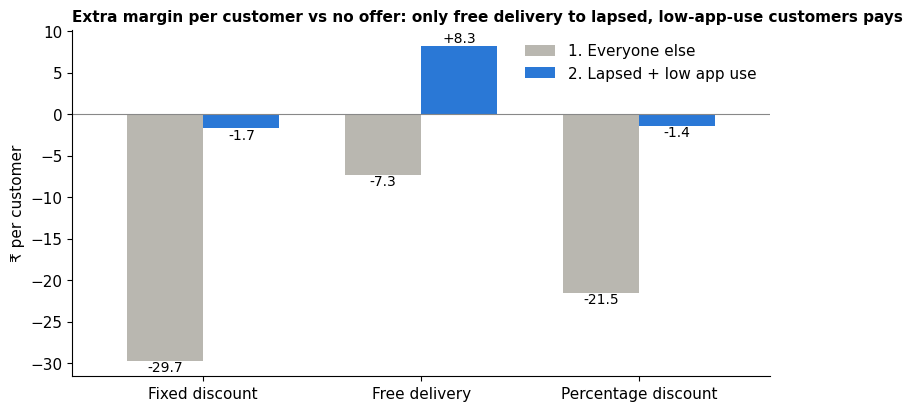

,customer_group,offer_type,pct_redeemed,extra_margin_vs_no_offer,extra_orders_vs_no_offer
0,1. Everyone else,Fixed discount,36.3,-29.7,0.11
1,1. Everyone else,Free delivery,35.1,-7.3,0.10
3,1. Everyone else,Percentage discount,35.2,-21.5,0.07
4,2. Lapsed + low app use,Fixed discount,22.5,-1.7,0.32
5,2. Lapsed + low app use,Free delivery,25.0,8.3,0.28
7,2. Lapsed + low app use,Percentage discount,24.7,-1.4,0.25


In [64]:
base2 = promo2[promo2.offer_type == "No offer"].set_index("customer_group")
promo2["extra_margin_vs_no_offer"] = promo2.apply(lambda r: round(r.margin_per_customer - base2.loc[r.customer_group, "margin_per_customer"], 1), axis=1)
promo2["extra_orders_vs_no_offer"] = promo2.apply(lambda r: round(r.orders_per_customer - base2.loc[r.customer_group, "orders_per_customer"], 2), axis=1)
promo2["margin_per_customer"] = promo2["margin_per_customer"].round(1)   # round only after subtracting
result = promo2[promo2.offer_type != "No offer"][["customer_group", "offer_type", "pct_redeemed", "extra_margin_vs_no_offer", "extra_orders_vs_no_offer"]]

table = result.pivot(index="offer_type", columns="customer_group", values="extra_margin_vs_no_offer")
ax = table.plot(kind="bar", rot=0, color=[GREY, BLUE], width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt="%+.1f", fontsize=10)
ax.axhline(0, color="#888", linewidth=0.8)
ax.set_title("Extra margin per customer vs no offer: only free delivery to lapsed, low-app-use customers pays", loc="left", fontsize=11)
ax.set_ylabel("₹ per customer"); ax.set_xlabel(""); ax.legend(title="", frameon=False)
plt.savefig(f"{CHARTS}/6_promo_result.png", dpi=200, bbox_inches="tight"); plt.show()
result

What I see:
- As run, the campaign lost money. Treatment customers ordered a bit more (1.37 vs 1.21 orders) but gave ₹66.4 of margin each, against ₹78.8 in control. The exact gap is ₹12.5 less per customer (Step 6 prints it).
- Redemption is misleading. Active customers redeemed most (about 37%), but no offer paid for them: the two discounts clearly lowered their margin, and free delivery didn't help either. The extra orders didn't cover the cost of the offers.
- Lapsed + low app use, with free delivery, is the only group where an offer pays: ₹8.3 more margin per customer and 0.28 more orders. It's also the cheapest offer (₹39). With lapsed alone the gain was only ₹4.7, because lapsed customers who still use the app a lot behave like active ones.
- For everyone else, the discounts lose money (percentage off −₹21.5, fixed ₹100 off −₹29.7) and free delivery doesn't help (−₹7.3).
- Caution: the winning cell has about 500 customers getting free delivery and 930 getting no offer, and I tried 12 segment × offer cells, so the best one may be partly luck. Next I check where the gain comes from.

### Where does the +₹8.3 come from?
37% of the "lapsed + low app use" group are customers with no orders in 2025 (`historical_orders_12m = 0`, a field the Data Dictionary marks as known at decision time). I split the result by that.

In [65]:
dormant = run("""
SELECT CASE WHEN c.historical_orders_12m = 0 THEN '1. No orders in 2025 (dormant)'
            WHEN c.days_since_last_order > 90 THEN '2. Lapsed, but ordered in 2025'
            ELSE '3. Active' END                     AS customer_group,
       a.offer_type,
       COUNT(*)                                       AS customers,
       AVG(a.post_campaign_margin_inr)                AS margin_per_customer
FROM campaign_assignments a
JOIN customers c ON a.customer_id = c.customer_id
GROUP BY customer_group, a.offer_type
ORDER BY customer_group, a.offer_type
""")
dormant

,customer_group,offer_type,customers,margin_per_customer
0,1. No orders in 2025 (dormant),Fixed discount,242,30.452066
1,1. No orders in 2025 (dormant),Free delivery,240,35.922458
2,1. No orders in 2025 (dormant),No offer,451,18.886120
3,1. No orders in 2025 (dormant),Percentage discount,308,24.007045
4,"2. Lapsed, but ordered in 2025",Fixed discount,532,46.035789
5,"2. Lapsed, but ordered in 2025",Free delivery,511,58.990274
6,"2. Lapsed, but ordered in 2025",No offer,921,59.660912
7,"2. Lapsed, but ordered in 2025",Percentage discount,661,47.196929
8,3. Active,Fixed discount,799,74.645569
9,3. Active,Free delivery,808,100.047599


                customer_group               offer  extra_margin  low_95  high_95
1. No orders in 2025 (dormant)      Fixed discount          11.6     2.2     20.9
1. No orders in 2025 (dormant) Percentage discount           5.1    -2.9     13.1
1. No orders in 2025 (dormant)       Free delivery          17.0     7.9     26.1
2. Lapsed, but ordered in 2025      Fixed discount         -13.6   -23.0     -4.2
2. Lapsed, but ordered in 2025 Percentage discount         -12.5   -20.6     -4.3
2. Lapsed, but ordered in 2025       Free delivery          -0.7    -9.1      7.7
                     3. Active      Fixed discount         -34.8   -44.5    -25.0
                     3. Active Percentage discount         -22.0   -31.0    -13.0
                     3. Active       Free delivery          -9.4   -18.8      0.1
Free delivery, lapsed + low app, no 2025 orders: +19.0 (95% range +8.5 to +29.5)
Free delivery, lapsed + low app, ordered in 2025: +1.7 (95% range -8.4 to +11.8)


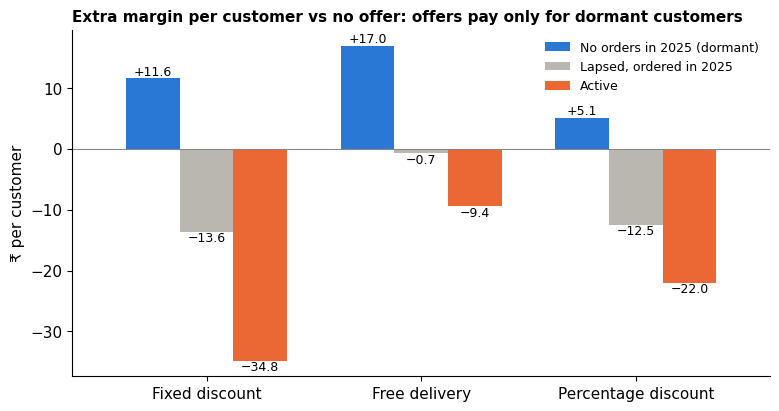

In [66]:
# Extra margin vs no offer, with a simple 95% range (difference ± 1.96 × standard error), for each group and offer
detail = run("""
SELECT CASE WHEN c.historical_orders_12m = 0 THEN '1. No orders in 2025 (dormant)'
            WHEN c.days_since_last_order > 90 THEN '2. Lapsed, but ordered in 2025'
            ELSE '3. Active' END AS customer_group,
       CASE WHEN c.days_since_last_order > 90 AND c.app_sessions_30d <= 7 THEN 1 ELSE 0 END AS lapsed_low_app,
       a.offer_type, a.post_campaign_margin_inr AS margin
FROM campaign_assignments a JOIN customers c ON a.customer_id = c.customer_id
""")
rows = []
for group, g in detail.groupby("customer_group"):
    no_offer = g[g.offer_type == "No offer"]["margin"]
    for offer in ["Fixed discount", "Percentage discount", "Free delivery"]:
        got = g[g.offer_type == offer]["margin"]
        diff = got.mean() - no_offer.mean()
        se = (got.var() / len(got) + no_offer.var() / len(no_offer)) ** 0.5
        rows.append((group, offer, round(diff, 1), round(diff - 1.96 * se, 1), round(diff + 1.96 * se, 1)))
by_group = pd.DataFrame(rows, columns=["customer_group", "offer", "extra_margin", "low_95", "high_95"])
print(by_group.to_string(index=False))

# Inside the lapsed + low app use group: with vs without 2025 orders (free delivery)
for label, part in [("lapsed + low app, no 2025 orders", detail[(detail.lapsed_low_app == 1) & detail.customer_group.str.startswith("1")]),
                    ("lapsed + low app, ordered in 2025", detail[(detail.lapsed_low_app == 1) & ~detail.customer_group.str.startswith("1")])]:
    got = part[part.offer_type == "Free delivery"]["margin"]; none = part[part.offer_type == "No offer"]["margin"]
    diff = got.mean() - none.mean(); se = (got.var() / len(got) + none.var() / len(none)) ** 0.5
    print(f"Free delivery, {label}: {diff:+.1f} (95% range {diff - 1.96 * se:+.1f} to {diff + 1.96 * se:+.1f})")

# Chart: extra margin vs no offer, by group and offer
table = by_group.pivot(index="offer", columns="customer_group", values="extra_margin")
table.columns = ["No orders in 2025 (dormant)", "Lapsed, ordered in 2025", "Active"]
ax = table.plot(kind="bar", rot=0, color=[BLUE, GREY, ORANGE], width=0.75)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:+.1f}".replace("-", "−") for v in container.datavalues], fontsize=9)
ax.axhline(0, color="#888", linewidth=0.8)
ax.set_title("Extra margin per customer vs no offer: offers pay only for dormant customers", loc="left", fontsize=11)
ax.set_ylabel("₹ per customer"); ax.set_xlabel(""); ax.legend(title="", frameon=False, fontsize=9)
plt.savefig(f"{CHARTS}/6_promo_by_group.png", dpi=200, bbox_inches="tight"); plt.show()

What I see:
- Almost all of the +₹8.3 comes from customers with no 2025 orders. For them free delivery adds about +₹19; for lapsed customers who did order in 2025 it's about +₹2, which is no real effect.
- Across all customers with no 2025 orders, free delivery adds about +₹17 per customer (95% range about +₹8 to +₹26), and even the fixed discount pays a little. For lapsed customers who ordered in 2025, the discounts clearly lose money and free delivery breaks even.
- So the clearest target is dormant customers: no orders in the last 12 months. One caution: these customers' records have a date quirk (Step 1), so the offer should be re-tested before a full rollout.

In [67]:
df = run("""
SELECT 'Membership' AS split, c.membership_status AS grp,
       ROUND(AVG(CASE WHEN a.assignment_group = 'Treatment' THEN a.post_campaign_margin_inr END)
           - AVG(CASE WHEN a.assignment_group = 'Control'   THEN a.post_campaign_margin_inr END), 1) AS offer_minus_no_offer
FROM campaign_assignments a JOIN customers c ON a.customer_id = c.customer_id GROUP BY c.membership_status
UNION ALL
SELECT 'City tier', c.city_tier,
       ROUND(AVG(CASE WHEN a.assignment_group = 'Treatment' THEN a.post_campaign_margin_inr END)
           - AVG(CASE WHEN a.assignment_group = 'Control'   THEN a.post_campaign_margin_inr END), 1)
FROM campaign_assignments a JOIN customers c ON a.customer_id = c.customer_id GROUP BY c.city_tier
UNION ALL
SELECT 'Channel', c.acquisition_channel,
       ROUND(AVG(CASE WHEN a.assignment_group = 'Treatment' THEN a.post_campaign_margin_inr END)
           - AVG(CASE WHEN a.assignment_group = 'Control'   THEN a.post_campaign_margin_inr END), 1)
FROM campaign_assignments a JOIN customers c ON a.customer_id = c.customer_id GROUP BY c.acquisition_channel
""")
df

,split,grp,offer_minus_no_offer
0,Membership,Annual member,-9.6
1,Membership,Monthly member,-16.8
2,Membership,Non-member,-11.4
3,City tier,Metro,-14.8
4,City tier,Tier 2,-10.1
5,Channel,Affiliate,-16.0
6,Channel,Marketplace,3.0
7,Channel,Organic,-13.9
8,Channel,Paid Social,-18.6
9,Channel,Referral,-10.5


What I see: the offers lose money in almost every split. Membership, city tier and channel don't rescue them. The one small exception is customers who came through the Marketplace channel (+₹3), which is too small to act on. What separates the customers an offer can win back is whether they ordered at all in 2025 (the section above).

## Step 6 · Recommendations for next quarter
I sized each idea with simple arithmetic on the numbers above.

In [68]:
# 1) Promo: free delivery only for lapsed customers with low app use
target_share = run("SELECT AVG(CASE WHEN days_since_last_order > 90 AND app_sessions_30d <= 7 THEN 1.0 ELSE 0 END) AS s FROM customers").s[0]
dormant_share = run("SELECT AVG(CASE WHEN historical_orders_12m = 0 THEN 1.0 ELSE 0 END) AS s FROM customers").s[0]
dormant_gain = by_group[(by_group.customer_group.str.startswith("1")) & (by_group.offer == "Free delivery")].extra_margin.iloc[0]
as_run = run("""SELECT AVG(CASE WHEN assignment_group='Treatment' THEN post_campaign_margin_inr END)
                     - AVG(CASE WHEN assignment_group='Control' THEN post_campaign_margin_inr END) AS d
                FROM campaign_assignments""").d[0]
target_gain = result[(result.customer_group.str.startswith("2")) & (result.offer_type == "Free delivery")].extra_margin_vs_no_offer.iloc[0]
print(f"Per 1,000 customers, if everyone gets an offer:            ₹{as_run * 1000:,.0f}  (the test's result per offered customer)")
print(f"Per 1,000 customers, free delivery to lapsed + low app use: ₹{target_gain * target_share * 1000:,.0f}  ({target_share:.1%} of customers get the offer)")
print(f"Per 1,000 customers, free delivery to dormant customers:     ₹{dormant_gain * dormant_share * 1000:,.0f}  ({dormant_share:.1%} of customers get the offer)")

Per 1,000 customers, if everyone gets an offer:            ₹-12,461  (the test's result per offered customer)
Per 1,000 customers, free delivery to lapsed + low app use: ₹2,704  (32.6% of customers get the offer)
Per 1,000 customers, free delivery to dormant customers:     ₹2,637  (15.5% of customers get the offer)


In [69]:
# 1b) Small baskets: what if orders under ₹400 got no discount and customers still ordered? (upper limit)
small = basket.iloc[0]
upper = small.avg_discount * small.orders
total_margin = run("SELECT SUM(contribution_margin_inr) AS t FROM orders").t[0]
print(f"{small.orders:,} orders under ₹400 get ₹{small.avg_discount} off on average and make ₹{small.margin_per_order} each")
print(f"Upper limit if none of them stopped ordering: +₹{upper:,.0f} = {upper / total_margin:.1%} of total margin (some customers would stop, so test it)")

2,694 orders under ₹400 get ₹44.9 off on average and make ₹-10.4 each
Upper limit if none of them stopped ordering: +₹120,961 = 9.1% of total margin (some customers would stop, so test it)


In [70]:
# 2) Delivery promise by distance: 25 min within 2 km, 30 min beyond.
#    Actual delivery time doesn't depend on the promise (it averages about 19 minutes for 20, 25 and 30-minute promises),
#    so I can check every delivered order against the promise it WOULD get under the new rule.
check_rule = run("""
SELECT promised_minutes,
       CASE WHEN delivery_distance_km <= 2 THEN 25 ELSE 30 END AS new_promise,
       actual_delivery_minutes
FROM orders
WHERE cancelled_flag = 0
""")
print("Average actual minutes by today's promise:", check_rule.groupby("promised_minutes")["actual_delivery_minutes"].mean().round(1).to_dict())
new_late = 100 * (check_rule["actual_delivery_minutes"] > check_rule["new_promise"]).mean()
longer = 100 * (check_rule["new_promise"] > check_rule["promised_minutes"]).mean()
shorter = 100 * (check_rule["new_promise"] < check_rule["promised_minutes"]).mean()
print(f"Late deliveries today: {kpi.pct_late[0]}%   With the new promise rule: {new_late:.1f}%")
print(f"Orders that would see a longer promise: {longer:.1f}%, a shorter one: {shorter:.1f}%")
print(f"For comparison, 30 minutes for every order: {100 * (check_rule['actual_delivery_minutes'] > 30).mean():.1f}% late, but nobody keeps a fast promise")

Average actual minutes by today's promise: {20: 18.9, 25: 18.9, 30: 18.9}
Late deliveries today: 17.3%   With the new promise rule: 7.5%
Orders that would see a longer promise: 40.5%, a shorter one: 18.4%
For comparison, 30 minutes for every order: 5.6% late, but nobody keeps a fast promise


In [71]:
# 3) Stock accuracy: if the 9 weakest stores did as well as the 90-95% group
weak, middle = inv.iloc[0], inv.iloc[1]
gain_per_order = middle.margin_per_order - weak.margin_per_order
total_margin = run("SELECT SUM(contribution_margin_inr) AS t FROM orders").t[0]
extra = gain_per_order * weak.orders
print(f"₹{gain_per_order:.1f} more per order x {weak.orders:,} orders = ₹{extra:,.0f} = {extra / total_margin:.1%} of total margin")

₹5.6 more per order x 7,414 orders = ₹41,518 = 3.1% of total margin


## Step 7 · Double-check with plain Python
I re-calculate a few key numbers a different way to make sure the SQL is right.

In [72]:
orders = pd.read_excel(excel_file, sheet_name="orders")
camp = pd.read_excel(excel_file, sheet_name="campaign_assignments")
checks = pd.DataFrame({
    "number": ["Margin per order (₹)", "% orders late", "% orders losing money", "Campaign: treatment minus control (₹)"],
    "from SQL": [kpi.margin_per_order_inr[0], kpi.pct_late[0], kpi.pct_orders_losing_money[0], round(as_run, 1)],
    "from Python": [round(orders.contribution_margin_inr.mean(), 1), round(100 * orders.late_delivery_flag.mean(), 1),
                    round(100 * (orders.contribution_margin_inr < 0).mean(), 1),
                    round(camp[camp.assignment_group == "Treatment"].post_campaign_margin_inr.mean()
                          - camp[camp.assignment_group == "Control"].post_campaign_margin_inr.mean(), 1)]})
checks["match"] = checks["from SQL"] == checks["from Python"]
checks

,number,from SQL,from Python,match
0,Margin per order (₹),44.3,44.3,True
1,% orders late,17.3,17.3,True
2,% orders losing money,21.0,21.0,True
3,Campaign: treatment minus control (₹),-12.5,-12.5,True


## Step 8 · More checks

A few more questions I wanted answered before trusting the story: do the tables hang together, how big are the leaks in other cuts of the data, which store numbers move together, and how sure can I be about the promo result.

### 8.1 · Do the tables join cleanly?

In [73]:
joins = run("""
SELECT (SELECT COUNT(*) FROM orders WHERE customer_id NOT IN (SELECT customer_id FROM customers)) AS orders_with_unknown_customer,
       (SELECT COUNT(*) FROM orders WHERE store_id NOT IN (SELECT store_id FROM stores))          AS orders_with_unknown_store,
       (SELECT COUNT(DISTINCT customer_id) FROM orders)                                         AS customers_who_ordered
""")
joins

,orders_with_unknown_customer,orders_with_unknown_store,customers_who_ordered
0,0,0,6759


In [74]:
# Is historical_margin_12m just the 2025 orders added up? (a correlation of 1.0 means "yes, exactly")
hist = run("""
SELECT c.historical_margin_12m, COALESCE(o.margin_2025, 0) AS margin_2025
FROM customers c
LEFT JOIN (SELECT customer_id, SUM(contribution_margin_inr) AS margin_2025 FROM orders GROUP BY customer_id) o
       ON c.customer_id = o.customer_id
""")
history_corr = hist["historical_margin_12m"].corr(hist["margin_2025"])
print("Correlation between historical_margin_12m and 2025 order margin:", round(history_corr, 2))

orders_per_store_per_day = 30000 / 36 / 365
print("Orders per store per day:", round(orders_per_store_per_day, 1), "-> this is a sample, so I talk in ₹ per order and %, not company totals")

Correlation between historical_margin_12m and 2025 order margin: 1.0
Orders per store per day: 2.3 -> this is a sample, so I talk in ₹ per order and %, not company totals


What I see: no broken links, and 6,759 of the 8,000 customers ordered in 2025. The history columns are exactly the 2025 orders added up, so I only use them to *describe* customers, never to predict repeat buying in the same year. About 2.3 orders per store per day means this is a sample, so I report ₹ per order and shares, not company totals.

### 8.2 · A few more health numbers

In [75]:
health2 = run("""
SELECT ROUND(100.0 * SUM(discount_inr) / SUM(basket_value_inr), 1)                     AS discounts_pct_of_sales,
       ROUND(100.0 * SUM(refund_inr) / SUM(basket_value_inr), 1)                       AS refunds_pct_of_sales,
       ROUND(100.0 * AVG(CASE WHEN refund_inr > 0 THEN 1 ELSE 0 END), 1)              AS pct_orders_with_a_refund,
       ROUND(100.0 * AVG(CASE WHEN stockout_item_count > 0 THEN 1 ELSE 0 END), 1)     AS pct_orders_with_a_stockout,
       ROUND(100.0 * AVG(service_contact_flag), 1)                                     AS pct_orders_contacting_support,
       ROUND(SUM(discount_inr), 0)                                                      AS total_discounts,
       ROUND(SUM(contribution_margin_inr), 0)                                           AS total_margin
FROM orders
""")
health2

,discounts_pct_of_sales,refunds_pct_of_sales,pct_orders_with_a_refund,pct_orders_with_a_stockout,pct_orders_contacting_support,total_discounts,total_margin
0,8.0,3.8,26.2,63.9,12.7,1343573.0,1328228.0


In [76]:
df = run("""
SELECT ROUND(100.0 * AVG(CASE WHEN refund_inr > 0 THEN 1 ELSE 0 END), 1) AS pct_loss_orders_with_refund
FROM orders
WHERE contribution_margin_inr < 0
""")
df

,pct_loss_orders_with_refund
0,72.3


In [77]:
df = run("""
SELECT strftime('%m', order_timestamp)                              AS month,
       ROUND(100.0 * AVG(late_delivery_flag), 1)                     AS pct_late,
       ROUND(100.0 * SUM(discount_inr) / SUM(basket_value_inr), 1)   AS discount_pct_of_sales
FROM orders
GROUP BY month
ORDER BY month
""")
df

,month,pct_late,discount_pct_of_sales
0,01,14.9,8.0
1,02,14.0,8.3
2,03,14.0,8.0
3,04,18.3,8.0
4,05,17.0,7.9
5,06,21.7,7.9
6,07,19.3,8.0
7,08,20.4,7.9
8,09,21.2,8.1
9,10,15.2,8.0


What I see: discounts are 8.0% of sales, which in rupees is about the same as all the margin we made in the year. Refunds are 3.8% of sales; about a quarter of orders get some refund, and 72% of loss-making orders have one. Lateness rises to about 19-22% from June to September, while the discount share stays flat at about 8% every month.

### 8.3 · Customers who lean on discounts

In [78]:
df = run("""
SELECT CASE WHEN discount_share <= 0.05 THEN '1. up to 5%'
            WHEN discount_share <= 0.08 THEN '2. 5-8%'
            WHEN discount_share <= 0.11 THEN '3. 8-11%'
            ELSE '4. over 11%' END                      AS discount_share_of_spend,
       COUNT(*)                                          AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1)          AS pct_repeat,
       ROUND(AVG(orders), 1)                             AS orders_per_customer,
       ROUND(AVG(margin_per_order), 1)                   AS margin_per_order_avg_of_customers,
       ROUND(SUM(total_margin) / SUM(orders), 1)         AS margin_per_order
FROM (SELECT c.customer_id, c.repeat_order_30d,
             COUNT(*)                                       AS orders,
             SUM(o.discount_inr) / SUM(o.basket_value_inr)  AS discount_share,
             AVG(o.contribution_margin_inr)                 AS margin_per_order,
             SUM(o.contribution_margin_inr)                 AS total_margin
      FROM orders o JOIN customers c ON o.customer_id = c.customer_id
      GROUP BY c.customer_id)
GROUP BY discount_share_of_spend
ORDER BY discount_share_of_spend
""")
df

,discount_share_of_spend,customers,pct_repeat,orders_per_customer,margin_per_order_avg_of_customers,margin_per_order
0,1. up to 5%,1730,23.1,2.7,74.1,69.5
1,2. 5-8%,2350,38.0,4.3,53.1,51.9
2,3. 8-11%,1883,43.2,5.6,37.2,36.7
3,4. over 11%,796,43.3,6.1,14.7,20.8


What I see: this is growth that looks good and isn't. Customers whose spend is more than 11% discount order the most (6.1 orders vs 2.7) and repeat at 43%, but earn only about ₹21 per order (counting every order), against ₹70 for customers who get little discount. (Averaging each customer's own figure gives ₹15 vs ₹74.) Repeat within 30 days mostly goes with how recently and often someone orders, so it rises with order count. A cap on the discount per order (say about 10% of the basket) would be worth testing.

### 8.4 · Broad baskets and members

In [79]:
df = run("""
SELECT CASE WHEN avg_categories <= 3 THEN '1. up to 3'
            WHEN avg_categories <= 5 THEN '2. 3-5'
            ELSE '3. more than 5' END             AS categories_per_order,
       COUNT(*)                                    AS customers,
       ROUND(100.0 * AVG(repeat_order_30d), 1)    AS pct_repeat
FROM (SELECT c.customer_id, c.repeat_order_30d, AVG(o.unique_category_count) AS avg_categories
      FROM orders o JOIN customers c ON o.customer_id = c.customer_id
      GROUP BY c.customer_id)
GROUP BY categories_per_order
ORDER BY categories_per_order
""")
df

,categories_per_order,customers,pct_repeat
0,1. up to 3,1598,23.0
1,2. 3-5,4448,42.7
2,3. more than 5,713,26.1


In [80]:
df = run("""
SELECT CASE WHEN c.membership_status = 'Non-member' THEN 'Non-member' ELSE 'Member' END AS membership,
       ROUND(100.0 * SUM(o.discount_inr) / SUM(o.basket_value_inr), 1)                  AS discount_pct_of_spend
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
GROUP BY membership
""")
df

,membership,discount_pct_of_spend
0,Member,6.6
1,Non-member,9.2


What I see: customers who buy across 3-5 categories per order repeat at about 43%, against about 23% for narrow baskets (very broad baskets, 5+, drop back to about 26%). Members get a smaller discount share (about 6.6% of their spend vs 9.2% for non-members) and earn more per order (Step 3).

### 8.5 · The busiest 20% of customers vs the rest

In [81]:
# Rank the customers who ordered from fewest to most orders, then cut them into 5 equal groups
busy = run("""
SELECT c.customer_id, c.historical_orders_12m AS orders, SUM(o.contribution_margin_inr) AS margin
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.customer_id
ORDER BY orders, c.customer_id
""")
busy["group"] = pd.qcut(range(len(busy)), 5, labels=["1. least busy 20%", "2", "3", "4", "5. busiest 20%"])
busy_table = busy.groupby("group", observed=True).agg(customers=("customer_id", "count"),
                                                      orders_per_customer=("orders", "mean"),
                                                      margin_per_customer=("margin", "sum"))
busy_table["margin_per_customer"] = busy_table["margin_per_customer"] / busy_table["customers"]
busy_table["margin_per_order"] = busy.groupby("group", observed=True)["margin"].sum() / busy.groupby("group", observed=True)["orders"].sum()
busy_table.round(1)

,customers,orders_per_customer,margin_per_customer,margin_per_order
group,,,,
1. least busy 20%,1352,1.0,59.0,56.6
2,1352,2.2,114.5,52.4
3,1351,3.5,177.6,51.5
4,1352,5.4,261.5,48.7
5. busiest 20%,1352,10.1,370.0,36.5


What I see: the busiest 20% earn about ₹36 per order against about ₹57 for the least busy 20%. They're still the most valuable customers in total (about ₹370 each in the year), so the fix is smaller discounts for them, not losing them.

### 8.6 · Peak hours and weather: margin as well as lateness

In [82]:
df = run("""
SELECT weather_flag,
       CASE WHEN peak_period_flag = 1 THEN 'Peak' ELSE 'Off-peak' END AS time_of_day,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(late_delivery_flag), 1)  AS pct_late,
       ROUND(AVG(contribution_margin_inr), 1)     AS margin_per_order
FROM orders
GROUP BY weather_flag, time_of_day
ORDER BY weather_flag, time_of_day
""")
df

,weather_flag,time_of_day,orders,pct_late,margin_per_order
0,Heat,Off-peak,2156,15.3,45.1
1,Heat,Peak,1257,31.7,33.4
2,Normal,Off-peak,12738,6.9,48.8
3,Normal,Peak,7520,20.1,41.5
4,Rain,Off-peak,4036,24.1,44.1
5,Rain,Peak,2293,47.5,33.8


What I see: peak hours in rain or heat are the worst slots on both counts: about 47% / 32% late and only about ₹33-34 margin per order, against 7% late and ₹49 at normal off-peak times.

### 8.7 · Across the 36 stores: what moves together? (correlation)
A correlation runs from -1 to +1. Close to +1 means two things rise together; close to -1 means one rises as the other falls; near 0 means no link. It shows things go together, not that one causes the other.

In [83]:
stores_table = run("""
SELECT s.store_id, s.inventory_accuracy_pct, s.staffing_fill_rate_pct,
       AVG(o.contribution_margin_inr) AS margin_per_order,
       AVG(o.stockout_item_count)     AS missing_items_per_order,
       AVG(o.refund_inr)              AS refund_per_order,
       AVG(o.late_delivery_flag)      AS late_rate,
       AVG(o.rating)                  AS rating
FROM orders o JOIN stores s ON o.store_id = s.store_id
GROUP BY s.store_id
""")
# One line of pandas: the correlation of each store number with stock accuracy and with staffing
correlations = stores_table.drop(columns="store_id").corr().loc[["inventory_accuracy_pct", "staffing_fill_rate_pct"]]
correlations.round(2)

,inventory_accuracy_pct,staffing_fill_rate_pct,margin_per_order,missing_items_per_order,refund_per_order,late_rate,rating
inventory_accuracy_pct,1.00,0.34,0.77,-1.00,-0.88,-0.41,0.99
staffing_fill_rate_pct,0.34,1.00,0.27,-0.34,-0.29,-0.66,0.36


In [84]:
# How many ₹ of margin per order go with 1 extra point of stock accuracy? (straight line through the 36 stores)
import numpy as np
slope, intercept = np.polyfit(stores_table["inventory_accuracy_pct"], stores_table["margin_per_order"], 1)
print(f"Each +1 point of stock accuracy goes with about +₹{slope:.2f} margin per order")

Each +1 point of stock accuracy goes with about +₹1.16 margin per order


What I see: store margin per order has a correlation of 0.77 with stock accuracy. Missing items move almost exactly opposite to it (-1.00), refunds strongly opposite (-0.88), and ratings almost exactly with it (0.99). Staffing goes with lateness instead (-0.66). Each extra point of stock accuracy goes with about ₹1.16 more margin per order.

### 8.8 · Stores split into four equal groups (quartiles) by stock accuracy
Another way to cut stores: split the orders into 4 equal groups by their store's stock accuracy (7,500 orders each), instead of using fixed 90% / 95% cut-offs.

In [85]:
quartiles = run("""
SELECT quartile,
       MIN(inventory_accuracy_pct)              AS lowest_accuracy,
       MAX(inventory_accuracy_pct)              AS highest_accuracy,
       COUNT(*)                                 AS orders,
       ROUND(AVG(stockout_item_count), 2)       AS missing_items_per_order,
       ROUND(AVG(refund_inr), 1)                AS refund_per_order,
       ROUND(AVG(contribution_margin_inr), 1)   AS margin_per_order,
       ROUND(AVG(rating), 2)                    AS avg_rating
FROM (SELECT o.*, s.inventory_accuracy_pct,
             NTILE(4) OVER (ORDER BY s.inventory_accuracy_pct) AS quartile   -- NTILE(4) = cut into 4 equal groups
      FROM orders o JOIN stores s ON o.store_id = s.store_id)
GROUP BY quartile
ORDER BY quartile
""")
quartiles

,quartile,lowest_accuracy,highest_accuracy,orders,missing_items_per_order,refund_per_order,margin_per_order,avg_rating
0,1,84.4,90.0,7500,1.77,26.8,38.5,3.83
1,2,90.0,93.3,7500,1.30,22.0,43.3,4.13
2,3,93.3,95.3,7500,0.97,20.1,45.4,4.31
3,4,95.3,98.8,7500,0.60,16.4,49.8,4.56


In [86]:
# If the bottom group did as well as the third group
gap = quartiles.margin_per_order[2] - quartiles.margin_per_order[0]
extra = gap * quartiles.orders[0]
total_margin = run("SELECT SUM(contribution_margin_inr) AS t FROM orders").t[0]
print(f"Bottom quartile earns ₹{gap:.1f} less per order than the third quartile")
print(f"Closing that gap: +₹{extra:,.0f} = +{extra / total_margin:.1%} of total margin")

Bottom quartile earns ₹6.9 less per order than the third quartile
Closing that gap: +₹51,750 = +3.9% of total margin


What I see: the bottom quarter (stock accuracy 84-90%) earns about ₹7 less per order than the third quarter, worth about +4% of total margin if the gap closed. My recommendation uses the simpler "below 90%" rule instead (₹5.6 gap to the 90-95% stores, about +3%), which is a bit more cautious. Both point to the same stores.

### 8.9 · Is being late costly in itself?
Far-away orders are both later and less profitable, so I compare late and on-time orders within the same distance band.

In [87]:
df = run("""
SELECT CASE WHEN delivery_distance_km <= 2 THEN '1. up to 2 km'
            WHEN delivery_distance_km <= 4 THEN '2. 2-4 km'
            ELSE '3. over 4 km' END                   AS distance,
       CASE WHEN late_delivery_flag = 1 THEN 'Late' ELSE 'On time' END AS delivery,
       COUNT(*)                                       AS orders,
       ROUND(AVG(contribution_margin_inr), 1)         AS margin_per_order,
       ROUND(AVG(rating), 2)                          AS avg_rating,
       ROUND(100.0 * AVG(service_contact_flag), 1)    AS pct_contacted_support
FROM orders
WHERE cancelled_flag = 0
GROUP BY distance, delivery
ORDER BY distance, delivery
""")
df

,distance,delivery,orders,margin_per_order,avg_rating,pct_contacted_support
0,1. up to 2 km,Late,815,48.4,3.93,18.4
1,1. up to 2 km,On time,10089,57.1,4.27,10.9
2,2. 2-4 km,Late,2830,40.4,3.91,18.6
3,2. 2-4 km,On time,12176,47.5,4.28,11.1
4,3. over 4 km,Late,1485,36.0,3.81,19.4
5,3. over 4 km,On time,2300,38.6,4.28,11.7


What I see: in every distance band a late order earns about ₹3-9 less, is rated about 0.4 lower, and leads to about 1.7 times as many support contacts.

### 8.10 · What does distance cost?

In [88]:
df = run("""
SELECT CASE WHEN delivery_distance_km <= 1 THEN '1. up to 1 km'
            WHEN delivery_distance_km <= 2 THEN '2. 1-2 km'
            WHEN delivery_distance_km <= 3 THEN '3. 2-3 km'
            WHEN delivery_distance_km <= 4 THEN '4. 3-4 km'
            ELSE '5. over 4 km' END                AS distance,
       COUNT(*)                                    AS orders,
       ROUND(AVG(delivery_cost_inr), 1)            AS delivery_cost,
       ROUND(AVG(contribution_margin_inr), 1)      AS margin_per_order,
       ROUND(100.0 * AVG(late_delivery_flag), 1)   AS pct_late
FROM orders
GROUP BY distance
ORDER BY distance
""")
df

,distance,orders,delivery_cost,margin_per_order,pct_late
0,1. up to 1 km,3720,26.0,54.8,4.1
1,2. 1-2 km,7286,31.1,50.8,9.2
2,3. 2-3 km,8691,36.2,43.5,14.9
3,4. 3-4 km,6475,41.5,38.8,24.2
4,5. over 4 km,3828,47.8,32.8,39.2


In [89]:
# Extra delivery cost for each extra km (straight line through all delivered orders)
d = run("SELECT delivery_distance_km, delivery_cost_inr FROM orders WHERE cancelled_flag = 0")
cost_per_km, base_cost = np.polyfit(d["delivery_distance_km"], d["delivery_cost_inr"], 1)
print(f"Each extra km adds about ₹{cost_per_km:.1f} of delivery cost")

Each extra km adds about ₹5.4 of delivery cost


What I see: orders over 4 km earn about ₹33 per order against about ₹55 under 1 km, and each extra km adds about ₹5 of delivery cost.

### 8.11 · A second promise rule I tried
Three distance bands: 20 minutes up to 1 km, 25 minutes from 1 to 3 km, and 30 minutes beyond. First I estimate it from today's late rate for each distance and promise, then I check it order by order like in Step 6.

In [90]:
five = run("""
SELECT CASE WHEN delivery_distance_km <= 1 THEN '0-1'
            WHEN delivery_distance_km <= 2 THEN '1-2'
            WHEN delivery_distance_km <= 3 THEN '2-3'
            WHEN delivery_distance_km <= 4 THEN '3-4'
            ELSE '4+' END                       AS band,
       promised_minutes,
       COUNT(*)                                 AS orders,
       AVG(late_delivery_flag)                  AS late_rate
FROM orders
WHERE cancelled_flag = 0
GROUP BY band, promised_minutes
""")
five

,band,promised_minutes,orders,late_rate
0,0-1,20,893,0.135498
1,0-1,25,916,0.026201
2,0-1,30,1874,0.003202
3,1-2,20,1823,0.266045
4,1-2,25,1800,0.068889
5,1-2,30,3598,0.015286
6,2-3,20,2197,0.385981
7,2-3,25,2117,0.143127
8,2-3,30,4287,0.030091
9,3-4,20,1539,0.557505


In [91]:
old_rule = {"0-1": 20, "1-2": 25, "2-3": 25, "3-4": 30, "4+": 30}
late = five.set_index(["band", "promised_minutes"])["late_rate"]
orders_in_band = five.groupby("band")["orders"].sum()

expected_late = sum(late[(band, minutes)] * orders_in_band[band] for band, minutes in old_rule.items()) / orders_in_band.sum()
fast_share = sum(orders_in_band[band] for band, minutes in old_rule.items() if minutes <= 25) / orders_in_band.sum()
fast_today = run("SELECT AVG(CASE WHEN promised_minutes <= 25 THEN 1.0 ELSE 0 END) AS s FROM orders WHERE cancelled_flag = 0").s[0]
print(f"Five-band rule, estimated: late orders {expected_late:.1%}; orders still promised 25 min or less: {fast_share:.0%} (today {fast_today:.0%})")

# Direct check, the same way as Step 6: compare each delivered order's actual minutes with its new promise
direct = run("""
SELECT actual_delivery_minutes,
       CASE WHEN delivery_distance_km <= 1 THEN 20 WHEN delivery_distance_km <= 3 THEN 25 ELSE 30 END AS new_promise
FROM orders WHERE cancelled_flag = 0
""")
print(f"Direct check of the same rule: {100 * (direct.actual_delivery_minutes > direct.new_promise).mean():.1f}% late")

Five-band rule, estimated: late orders 11.8%; orders still promised 25 min or less: 66% (today 50%)
Direct check of the same rule: 12.0% late


What I see: the five-band rule gives about 12% late (11.8% estimated, 12.0% checked order by order) and keeps a fast promise (25 minutes or less) for 66% of orders. My simpler rule in Step 6 (25 minutes within 2 km, 30 beyond) gives about 7.5% late but shows fewer fast promises. It's a trade-off between being on time and looking fast, and a pilot would tell us which one customers prefer.

### 8.12 · How sure are we about the promo results? (95% confidence ranges)
Each promo number comes from a few hundred customers, so it has some luck in it. A simple 95% range is:

difference ± 1.96 × standard error, where standard error = √(spread² of offer group ÷ its size + spread² of no-offer group ÷ its size).

If the whole range is above zero, the offer really helped; if it's all below zero, it really hurt; if it crosses zero, we can't tell.

In [92]:
promo_data = run("""
SELECT a.offer_type, a.post_campaign_margin_inr AS margin,
       CASE WHEN c.historical_orders_12m = 0 THEN 'Dormant (no 2025 orders)'
            ELSE CASE WHEN c.days_since_last_order > 90 THEN 'Lapsed' ELSE 'Active' END
                 || ' + ' ||
                 CASE WHEN c.app_sessions_30d <= 7 THEN 'low app use' ELSE 'high app use' END
       END AS segment
FROM campaign_assignments a JOIN customers c ON a.customer_id = c.customer_id
""")
promo_data_all = promo_data.assign(segment="All customers")

rows = []
for segment, group in pd.concat([promo_data_all, promo_data]).groupby("segment"):
    no_offer = group[group.offer_type == "No offer"]["margin"]
    for offer in ["Fixed discount", "Percentage discount", "Free delivery"]:
        got_offer = group[group.offer_type == offer]["margin"]
        difference = got_offer.mean() - no_offer.mean()
        standard_error = (got_offer.var() / len(got_offer) + no_offer.var() / len(no_offer)) ** 0.5
        low, high = difference - 1.96 * standard_error, difference + 1.96 * standard_error
        verdict = "helped" if low > 0 else ("hurt" if high < 0 else "can't tell")
        rows.append((segment, offer, len(got_offer), round(difference, 1), round(low, 1), round(high, 1), verdict))

ranges = pd.DataFrame(rows, columns=["segment", "offer", "customers_with_offer", "extra_margin", "low_95", "high_95", "verdict"])
ranges

,segment,offer,customers_with_offer,extra_margin,low_95,high_95,verdict
0,Active + high app use,Fixed discount,539,-40.5,-53.2,-27.7,hurt
1,Active + high app use,Percentage discount,693,-25.1,-37.0,-13.2,hurt
2,Active + high app use,Free delivery,528,-14.5,-27.2,-1.8,hurt
3,Active + low app use,Fixed discount,260,-25.2,-37.5,-12.9,hurt
4,Active + low app use,Percentage discount,374,-13.6,-24.8,-2.5,hurt
5,Active + low app use,Free delivery,280,2.3,-8.9,13.5,can't tell
6,All customers,Fixed discount,1573,-20.6,-26.9,-14.4,hurt
7,All customers,Percentage discount,2036,-14.1,-19.8,-8.3,hurt
8,All customers,Free delivery,1559,-2.1,-8.2,4.0,can't tell
9,Dormant (no 2025 orders),Fixed discount,242,11.6,2.2,20.9,helped


In [93]:
# The same range a second way: re-shuffle the customers 2,000 times (a "bootstrap") and see where the answer lands
rng = np.random.default_rng(7)
target = promo_data[promo_data.segment == "Dormant (no 2025 orders)"]
free = target[target.offer_type == "Free delivery"]["margin"].to_numpy()
none = target[target.offer_type == "No offer"]["margin"].to_numpy()
results = []
for i in range(2000):
    results.append(rng.choice(free, len(free)).mean() - rng.choice(none, len(none)).mean())
print(f"Free delivery, dormant customers: +₹{free.mean() - none.mean():.1f}, 95% range ₹{np.percentile(results, 2.5):.1f} to ₹{np.percentile(results, 97.5):.1f}")

Free delivery, dormant customers: +₹17.0, 95% range ₹8.0 to ₹25.9


What I see:
- Dormant customers are the only group where offers clearly helped. Free delivery adds about +₹17 per customer (95% range about +₹8 to +₹26, and the reshuffle method agrees); the fixed discount also helps a little.
- For customers who did order in 2025, the discounts clearly hurt active customers and lapsed customers who still use the app a lot (worst: fixed discount, active with high app use, −₹40.5). Free delivery ranges from a clear loss (active with high app use, −₹14.5) to too close to call.
- Across all customers, fixed (−₹20.6) and percentage (−₹14.1) discounts clearly hurt; free delivery (−₹2.1) can't be told apart from zero.

### 8.13 · Holdout check: did I just get lucky picking that group?
I split customers randomly into two halves. I pick the best segment + offer using only the first half, then check it on the second half, which played no part in choosing it.

In [94]:
promo_data["half"] = np.where(np.random.default_rng(2026).random(len(promo_data)) < 0.5, "pick", "check")

def extra_margin_table(df):
    rows = []
    for segment, group in df.groupby("segment"):
        no_offer = group[group.offer_type == "No offer"]["margin"].mean()
        for offer in ["Fixed discount", "Percentage discount", "Free delivery"]:
            rows.append((segment, offer, round(group[group.offer_type == offer]["margin"].mean() - no_offer, 1)))
    return pd.DataFrame(rows, columns=["segment", "offer", "extra_margin"]).sort_values("extra_margin", ascending=False)

picked = extra_margin_table(promo_data[promo_data.half == "pick"])
best = picked.iloc[0]
checked = extra_margin_table(promo_data[promo_data.half == "check"])
on_other_half = checked[(checked.segment == best.segment) & (checked.offer == best.offer)].extra_margin.iloc[0]
print("Best on the first half:", best.segment, "+", best.offer, f"(+₹{best.extra_margin})")
print(f"Same choice on the second half: {'+' if on_other_half >= 0 else ''}₹{on_other_half}")
picked.head(3)

Best on the first half: Dormant (no 2025 orders) + Free delivery (+₹13.3)
Same choice on the second half: +₹20.7


,segment,offer,extra_margin
8,Dormant (no 2025 orders),Free delivery,13.3
6,Dormant (no 2025 orders),Fixed discount,10.8
5,Active + low app use,Free delivery,1.9


What I see: on the first half, the best segment and offer is free delivery for dormant customers (+₹13.3). On the second half, which played no part in picking it, the same choice gives +₹20.7. So the result holds up on customers it wasn't chosen on. Each half is small, so the exact rupee values move around.

### 8.14 · How many offers would we send?

In [95]:
share_targeted = run("SELECT AVG(CASE WHEN historical_orders_12m = 0 THEN 1.0 ELSE 0 END) AS s FROM customers").s[0]
share_sent_as_run = run("SELECT AVG(offer_sent_flag) AS s FROM campaign_assignments").s[0]
print(f"Per 10,000 customers: offers to everyone = 10,000; as the Q1 test ran = {share_sent_as_run * 10000:,.0f}; new rule = {share_targeted * 10000:,.0f}")
print(f"The new rule sends {1 - share_targeted:.0%} fewer offers than 'everyone' and {1 - share_targeted / share_sent_as_run:.0%} fewer than the Q1 test")

Per 10,000 customers: offers to everyone = 10,000; as the Q1 test ran = 6,460; new rule = 1,551
The new rule sends 84% fewer offers than 'everyone' and 76% fewer than the Q1 test


What I see: sending free delivery only to dormant customers means about 1,550 offers per 10,000 customers. That's 85% fewer than offering everyone and about 76% fewer than the Q1 test (6,460), and it still turns the promo from a loss into a gain.